# Object Detection for Automated Waste Sorting
## Detecting Waste Categories with YOLOv5s

**Students:** Chandana Lakshmisagara Udayashankar, Harshavardhini , Sahana Mysore Venkatesh , Shreyas Hosadurga Sadananda

**Course:** Computer Vision (Portfolio 1)

**Lecturer:** Prof. Dr. Dominik Seuß


---

## Table of Contents
1. [Introduction & Problem Statement](#intro)
2. [Dataset Overview](#dataset)
3. [Section 0: Setup](#setup)
4. [Section 1: Dataset Analysis](#analysis)
5. [Section 2: Duplicate Analysis](#duplicates)
6. [Section 3: Cleaning & Leakage-Free Split](#split)
7. [Section 4: Training Pipeline](#training)
8. [Section 5: Evaluation on the Test Set](#evaluation)
9. [Section 6: Visualization & Error Analysis](#errors)
10. [Section 7: Discussion & Conclusion](#conclusion)
11. [Section 8: Contribution Statement](#contribution)


---
## Introduction & Problem Statement <a id="intro"></a>

### Background
Modern waste management increasingly relies on automated sorting. Manual sorting is:
- slow and labour-intensive
- inconsistent between workers
- unpleasant and sometimes unsafe

### Problem Statement
**Goal:** detect waste objects in images and assign each one to a material category
(`biodegradable`, `cardboard`, `glass`, `metal`, `paper`, `plastic`).

### Why a one-stage detector (YOLOv5s)?
- real-time speed (about 6 ms per image in total on a T4)
- small model (9.1 M parameters), so it is suitable for conveyor-belt or edge hardware
- COCO-pretrained, so transfer learning works well with about 7 k training images
- one pass gives both the box and the class

### Our approach
| Step | Content | Section |
|---|---|---|
| 1 | Analyse the data and find risks (imbalance, small objects, duplicates) | 1 and 2 |
| 2 | Clean the labels and build a leakage-free train/val/test split | 3 |
| 3 | Design the training pipeline and train YOLOv5s | 4 |
| 4 | Evaluate on the untouched test set | 5 |
| 5 | Visualize and analyse errors, discuss limitations | 6 and 7 |

## 0.1 Install dependencies

In [ ]:
!pip install -q ultralytics iterative-stratification imagehash

## 0.2 Mount Drive, unzip the dataset, define configuration

In [ ]:
import os, shutil, zipfile, random, json, re, hashlib
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
from tqdm.auto import tqdm
from google.colab import drive

drive.mount("/content/drive")

ZIP_PATH = "/content/drive/MyDrive/GarbageDataset.zip"

SEED        = 42
PROJECT_DIR = Path("/content/Portfolio_1")
RAW_DIR     = PROJECT_DIR / "data" / "raw" / "GarbageDataset"
PROC_DIR    = PROJECT_DIR / "data" / "processed" / "GarbageDataset"
RUNS_DIR    = PROJECT_DIR / "runs"
TMP_DIR     = PROJECT_DIR / "data" / "_unzipped"
DRIVE_OUT   = Path("/content/drive/MyDrive/Portfolio_1_results")

IMG_DIR = RAW_DIR / "images"
LBL_DIR = RAW_DIR / "labels"

CLASS_NAMES = ["biodegradable", "cardboard", "glass", "metal", "paper", "plastic"]
NC    = len(CLASS_NAMES)
IMGSZ = 416

random.seed(SEED); np.random.seed(SEED)
PROJECT_DIR.mkdir(parents=True, exist_ok=True)
os.chdir(PROJECT_DIR)

if (IMG_DIR.is_dir() and LBL_DIR.is_dir()):
    print("Dataset already extracted, skipping unzip.")
else:
    assert Path(ZIP_PATH).exists(), f"Zip file not found: {ZIP_PATH}"
    if TMP_DIR.exists(): shutil.rmtree(TMP_DIR)
    TMP_DIR.mkdir(parents=True)
    print("Extracting zip ...")
    with zipfile.ZipFile(ZIP_PATH) as zf:
        zf.extractall(TMP_DIR)
    candidates = [p.parent for p in TMP_DIR.rglob("images")
                  if p.is_dir() and (p.parent / "labels").is_dir() and "__MACOSX" not in p.parts]
    assert candidates, "No folder containing both 'images' and 'labels' found in the zip."
    source_dir = min(candidates, key=lambda p: len(p.parts))
    RAW_DIR.parent.mkdir(parents=True, exist_ok=True)
    if RAW_DIR.exists(): shutil.rmtree(RAW_DIR)
    shutil.move(str(source_dir), str(RAW_DIR))
    shutil.rmtree(TMP_DIR, ignore_errors=True)

image_files = sorted(IMG_DIR.glob("*.jpg"))
label_files = sorted(LBL_DIR.glob("*.txt"))
print("Images:", len(image_files), "| Labels:", len(label_files))

Mounted at /content/drive
Extracting zip ...
Images: 10464 | Labels: 10464


## 0.3 Check the environment (GPU, library versions)

In [ ]:
import torch, torchvision, ultralytics, cv2
print("PyTorch:", torch.__version__, "| Torchvision:", torchvision.__version__)
print("Ultralytics:", ultralytics.__version__, "| OpenCV:", cv2.__version__)
print("CUDA available:", torch.cuda.is_available())
if torch.cuda.is_available():
    DEVICE = 0
    print("GPU:", torch.cuda.get_device_name(0))
else:
    DEVICE = "cpu"
    print("WARNING: no GPU. Runtime > Change runtime type > T4 GPU")

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings
PyTorch: 2.14.1+cu130 | Torchvision: 0.29.1+cu130
Ultralytics: 8.4.213 | OpenCV: 4.14.0
CUDA available: True
GPU: Tesla T4


# 1. Dataset Analysis (Task 1)

We analyse the data before designing the pipeline. Every finding is linked to a design decision for the training and evaluation pipeline.

## 1.1 Load all annotations into one table

In [ ]:
rows, malformed = [], []
for lp in label_files:
    for ln, line in enumerate(lp.read_text().splitlines(), 1):
        parts = line.split()
        if not parts:
            continue
        if len(parts) != 5:
            malformed.append((lp.name, ln, line[:60])); continue
        c, xc, yc, w, h = parts
        rows.append((lp.stem, int(float(c)), float(xc), float(yc), float(w), float(h), ln))

ann = pd.DataFrame(rows, columns=["image", "cls", "xc", "yc", "w", "h", "line"])
ann["cls_name"] = ann["cls"].map(dict(enumerate(CLASS_NAMES)))
ann["w_px"], ann["h_px"] = ann["w"] * IMGSZ, ann["h"] * IMGSZ
ann["area_px"] = ann["w_px"] * ann["h_px"]
ann["area_pct"] = ann["w"] * ann["h"] * 100

all_images = [p.stem for p in image_files]
print("Annotation rows       :", len(ann))
print("Malformed lines       :", len(malformed))
print("Images w/o label file :", len(set(all_images) - {p.stem for p in label_files}))
print("Class IDs found       :", sorted(int(c) for c in ann["cls"].unique()))
ann.head()

Annotation rows       : 74090
Malformed lines       : 0
Images w/o label file : 0
Class IDs found       : [0, 1, 2, 3, 4, 5]


,image,cls,xc,yc,w,h,line,cls_name,w_px,h_px,area_px,area_pct
0,biodegradable1000_jpg.rf.9407ff66b4ccd9f8eb554...,0,0.735577,0.659856,0.521635,0.536058,1,biodegradable,217.0,223.0,48391.0,27.962625
1,biodegradable1000_jpg.rf.9407ff66b4ccd9f8eb554...,0,0.764423,0.902644,0.324519,0.185096,2,biodegradable,135.0,77.0,10395.0,6.006726
2,biodegradable1000_jpg.rf.9407ff66b4ccd9f8eb554...,0,0.932692,0.850962,0.127404,0.288462,3,biodegradable,53.0,120.0,6360.0,3.675111
3,biodegradable1000_jpg.rf.9407ff66b4ccd9f8eb554...,0,0.905048,0.332933,0.181490,0.365385,4,biodegradable,75.5,152.0,11476.0,6.631379
4,biodegradable1000_jpg.rf.9407ff66b4ccd9f8eb554...,0,0.959135,0.592548,0.073317,0.185096,5,biodegradable,30.5,77.0,2348.5,1.357075


## Dataset Overview <a id="dataset"></a>

**Garbage Detection Dataset** (provided with the assignment)

| Property | Value |
|---|---|
| Images | 10,464 (all 416 × 416 px, JPEG) |
| Annotations | YOLO format (`class x_center y_center width height`, normalised), 74,090 boxes |
| Classes | 6, with IDs 0–5 (names inferred from filename prefixes, see 1.7) |
| File names | Roboflow style (`<name>_jpg.rf.<hash>.jpg`), which suggests an augmented export and hence possible copies of the same photo |

**Consequences we check before training:** class imbalance, object size, crowding, annotation quality, and duplicate images that could leak between splits.

## 1.2 Image resolution

In [ ]:
sizes = {}
for p in tqdm(image_files, desc="reading sizes"):
    with Image.open(p) as im:
        sizes[im.size] = sizes.get(im.size, 0) + 1
print("Distinct image sizes:", sizes)

reading sizes:   0%|          | 0/10464 [00:00<?, ?it/s]

Distinct image sizes: {(416, 416): 10464}


## 1.3 Class distribution (boxes vs. images)
Class imbalance matters for the split (stratification), for the loss/training and for the metrics (per-class AP instead of only overall accuracy).

,class,boxes,boxes_%,images,images_%
0,biodegradable,45407,61.29,2287,21.86
1,cardboard,4698,6.34,1502,14.35
2,glass,7809,10.54,2684,25.65
3,metal,5841,7.88,1898,18.14
4,paper,4390,5.93,1768,16.90
5,plastic,5945,8.02,1464,13.99


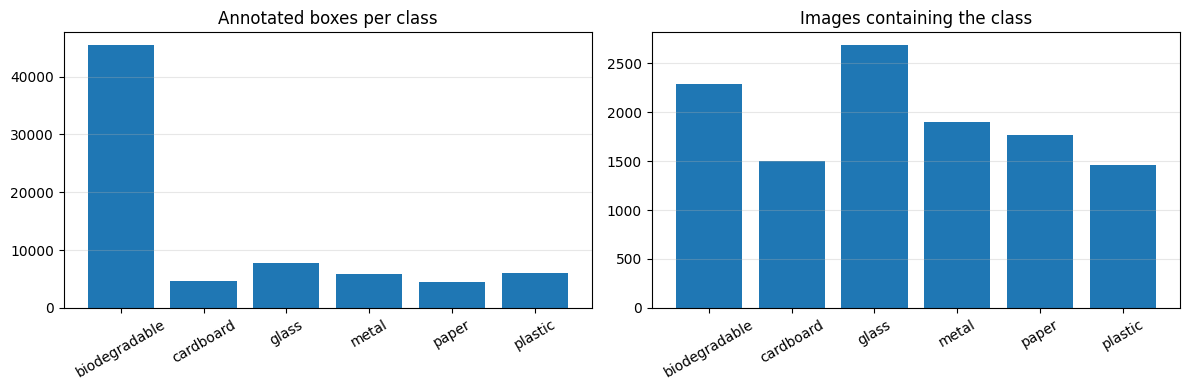

In [ ]:
box_cnt = ann["cls"].value_counts().sort_index()
img_cnt = ann.groupby("cls")["image"].nunique().sort_index()
dist = pd.DataFrame({"class": CLASS_NAMES,
                     "boxes": box_cnt.values, "boxes_%": (box_cnt.values / len(ann) * 100).round(2),
                     "images": img_cnt.values, "images_%": (img_cnt.values / len(all_images) * 100).round(2)})
display(dist)

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].bar(CLASS_NAMES, box_cnt.values); ax[0].set_title("Annotated boxes per class")
ax[1].bar(CLASS_NAMES, img_cnt.values); ax[1].set_title("Images containing the class")
for a in ax: a.tick_params(axis="x", rotation=30); a.grid(axis="y", alpha=.3)
plt.tight_layout(); plt.show()

### Observation: class distribution
- `biodegradable` has **45,407 boxes (61.3 %)** but appears in only **21.9 % of images**, so it comes as many small instances per image (about 20 per image).
- The other classes have 5.9–10.5 % of the boxes; `glass` appears in the most images (25.7 %).
- **Consequences:** we report per-class metrics (overall accuracy would be dominated by `biodegradable`), and we split with multi-label stratification so every class is in every split.

## 1.4 Objects per image (crowding)

count    10464.00
mean         7.08
std         19.10
min          1.00
25%          1.00
50%          2.00
75%          5.00
max        358.00
dtype: float64
Images with 1 object   : 5081 (48.6%)
Images with >=20 objects: 841 (8.0%)
Images with >=100 objects: 89
Max objects in one image: 358


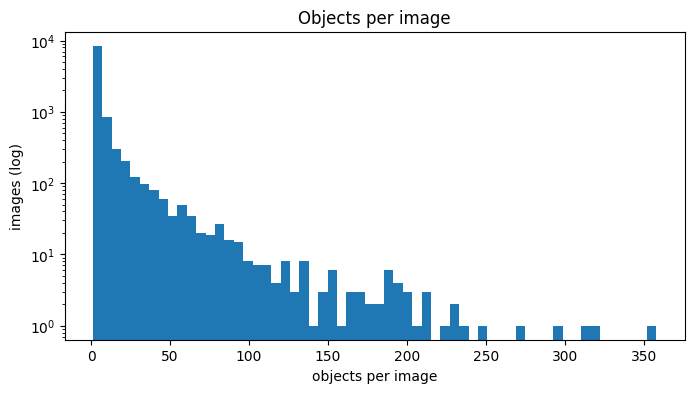

In [ ]:
objs = ann.groupby("image").size().reindex(all_images, fill_value=0)
print(objs.describe().round(2))
print("Images with 1 object   :", (objs == 1).sum(), f"({(objs == 1).mean()*100:.1f}%)")
print("Images with >=20 objects:", (objs >= 20).sum(), f"({(objs >= 20).mean()*100:.1f}%)")
print("Images with >=100 objects:", (objs >= 100).sum())
print("Max objects in one image:", objs.max())

fig, ax = plt.subplots(figsize=(8, 4))
ax.hist(objs, bins=60, log=True); ax.set_xlabel("objects per image"); ax.set_ylabel("images (log)")
ax.set_title("Objects per image"); plt.show()

### Observation: crowding
- Median is **2 objects per image**, and 48.6 % of images contain only one.
- 8 % of images have ≥ 20 objects, 89 have ≥ 100, and the maximum is **358**.
- **Consequences:** the default limit of 300 detections per image is too low, so we set `max_det=500`. Mosaic augmentation gives the model varied object density.

## 1.5 Bounding-box size and aspect ratio per class
Object sizes follow the COCO convention at 416 px: small < 32² px, medium 32²–96² px, large > 96² px.
Small objects are hard for detectors with stride-8 feature maps and are the main reason to consider a higher input resolution.

,boxes,median_area_pct,median_w_px,median_h_px,median_aspect,small_%,medium_%,large_%
cls_name,,,,,,,,
biodegradable,45407,1.04,41.0,44.0,0.90,36.4,46.7,16.9
cardboard,4698,12.24,153.0,147.0,1.00,3.9,28.7,67.4
glass,7809,9.24,105.0,124.0,0.88,10.7,26.9,62.4
metal,5841,4.81,89.0,94.0,0.95,14.3,38.0,47.7
paper,4390,19.48,186.0,196.0,1.00,5.1,22.8,72.1
plastic,5945,3.61,71.0,80.0,0.93,15.7,40.5,43.8


Overall share of small / medium / large boxes (%):
{'medium': 40.9, 'large': 32.7, 'small': 26.4}


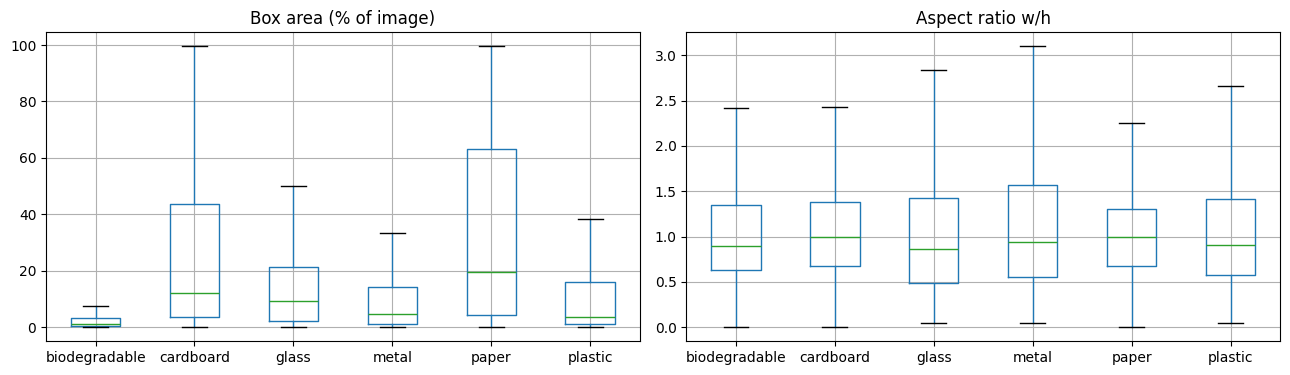

In [ ]:
def size_bucket(a):
    return np.where(a < 32**2, "small", np.where(a < 96**2, "medium", "large"))
ann["size"] = size_bucket(ann["area_px"].values)
ann["aspect"] = ann["w_px"] / ann["h_px"].replace(0, np.nan)

per_class = ann.groupby("cls_name").agg(
    boxes=("cls", "size"),
    median_area_pct=("area_pct", "median"),
    median_w_px=("w_px", "median"), median_h_px=("h_px", "median"),
    median_aspect=("aspect", "median"),
).round(2).reindex(CLASS_NAMES)
size_share = (pd.crosstab(ann["cls_name"], ann["size"], normalize="index") * 100).round(1).reindex(CLASS_NAMES)[["small", "medium", "large"]]
display(per_class.join(size_share.add_suffix("_%")))
print("Overall share of small / medium / large boxes (%):")
print((ann["size"].value_counts(normalize=True) * 100).round(1).to_dict())

fig, ax = plt.subplots(1, 2, figsize=(13, 4))
ann.boxplot(column="area_pct", by="cls_name", ax=ax[0], showfliers=False); ax[0].set_title("Box area (% of image)"); ax[0].set_xlabel("")
ann[ann["aspect"] < 5].boxplot(column="aspect", by="cls_name", ax=ax[1], showfliers=False); ax[1].set_title("Aspect ratio w/h"); ax[1].set_xlabel("")
plt.suptitle(""); plt.tight_layout(); plt.show()

### Observation: object size
- Overall 26.4 % small (< 32² px), 40.9 % medium, 32.7 % large.
- `biodegradable` boxes are tiny (median **1.0 % of the image, 41 × 44 px**, 36 % small), while `paper` (19.5 %) and `cardboard` (12.2 %) are large objects.
- **Consequences:** strong scale variation, so we use scale augmentation. Small objects are expected to be the weak point, so recall is analysed **by object size** in section 6.

## 1.6 Annotation validity

In [ ]:
bad_wh      = (ann["w"] <= 0) | (ann["h"] <= 0)
sub_pixel   = ((ann["w_px"] < 1) | (ann["h_px"] < 1)) & ~bad_wh
bad_center  = ~ann["xc"].between(0, 1) | ~ann["yc"].between(0, 1)
outside     = ((ann["xc"] - ann["w"]/2 < -1e-6) | (ann["xc"] + ann["w"]/2 > 1 + 1e-6) |
               (ann["yc"] - ann["h"]/2 < -1e-6) | (ann["yc"] + ann["h"]/2 > 1 + 1e-6))
print("zero / negative width or height :", bad_wh.sum())
print("sub-pixel boxes (<1 px side)    :", sub_pixel.sum())
print("centre outside image            :", bad_center.sum())
print("box extends outside image       :", outside.sum())
display(ann[bad_wh | sub_pixel | bad_center | outside].head(10))

zero / negative width or height : 17
sub-pixel boxes (<1 px side)    : 0
centre outside image            : 0
box extends outside image       : 0


,image,cls,xc,yc,w,h,line,cls_name,w_px,h_px,area_px,area_pct,size,aspect
2383,biodegradable1145_jpg.rf.b9e1cd4bc10c262d5314e...,0,0.457933,0.489183,0.000000,0.004808,58,biodegradable,0.0,2.0,0.0,0.0,small,0.0
3261,biodegradable1214_jpg.rf.4eda27606038a69880d17...,0,0.497596,0.000000,0.995192,0.000000,76,biodegradable,414.0,0.0,0.0,0.0,small,NaN
7940,biodegradable1465_jpg.rf.6554b314de4df3aed0117...,0,0.412260,0.895433,0.012019,0.000000,54,biodegradable,5.0,0.0,0.0,0.0,small,NaN
14470,biodegradable1740_jpg.rf.5f00e1157464c17341765...,0,0.256010,0.561298,0.000000,0.043269,64,biodegradable,0.0,18.0,0.0,0.0,small,0.0
19865,biodegradable1998_jpeg.rf.17921ee65cee3e00f10a...,0,0.478365,0.475962,0.062500,0.000000,261,biodegradable,26.0,0.0,0.0,0.0,small,NaN
20323,biodegradable2012_jpeg.rf.f157a4549b3da5de53b7...,0,0.224760,0.640625,0.004808,0.000000,26,biodegradable,2.0,0.0,0.0,0.0,small,NaN
25668,biodegradable2284_jpeg.rf.7f1b4eeb50bf5f036f56...,0,0.390625,0.307692,0.075721,0.000000,7,biodegradable,31.5,0.0,0.0,0.0,small,NaN
28480,biodegradable366_jpg.rf.09e6cd29dee38feb3b4df8...,0,0.441106,0.391827,0.048077,0.000000,18,biodegradable,20.0,0.0,0.0,0.0,small,NaN
30941,biodegradable403_jpg.rf.3176385ca1698f60cf5042...,0,0.074519,0.963942,0.043269,0.000000,43,biodegradable,18.0,0.0,0.0,0.0,small,NaN
31596,biodegradable419_jpg.rf.3cb6ccbe84af9a0d1a0832...,0,0.481971,0.155048,0.004808,0.000000,32,biodegradable,2.0,0.0,0.0,0.0,small,NaN


## 1.7 Is the class ID consistent with the filename prefix? (label noise / class-name check)
The dataset ships without class names. The filename prefix (`glass123_jpg.rf...`) indicates the *image category* the photo was collected under. Comparing it with the class IDs shows which ID means what, and how noisy the labels are.

In [ ]:
ann["prefix"] = ann["image"].str.extract(r"^([a-zA-Z]+)")[0].str.lower()
ct = pd.crosstab(ann["cls"], ann["prefix"])
display(ct)
dominant = ct.idxmax(axis=1)
print("Dominant filename prefix per class ID (-> inferred class name):")
print(dominant.to_dict())
print("Matches CLASS_NAMES:", [dominant[i] == CLASS_NAMES[i] for i in range(NC)])

prefix,biodegradable,cardboard,glass,metal,paper,plastic
cls,,,,,,
0,44905,31,333,112,18,8
1,224,4372,30,2,69,1
2,72,0,7719,11,3,4
3,112,2,1386,4328,3,10
4,139,62,3,0,4181,5
5,71,37,626,6,18,5187


Dominant filename prefix per class ID (-> inferred class name):
{0: 'biodegradable', 1: 'cardboard', 2: 'glass', 3: 'metal', 4: 'paper', 5: 'plastic'}
Matches CLASS_NAMES: [True, True, True, True, True, True]


### Observation: class names and label consistency
- The dominant filename prefix of each class ID gives a one-to-one mapping to the six names, so our class names are inferred, not official.
- 99 % (`biodegradable`, `glass`), 95 % (`paper`), 93 % (`cardboard`), 87 % (`plastic`) and 74 % (`metal`) of boxes sit in images with the matching prefix. Photos of one category often contain other materials (for example 1,386 `metal` boxes in `glass`-prefixed images), which is consistent with the 1,066 images that contain two or more classes.
- 17 boxes had zero width or height and are removed in section 3.

## 1.8 Multi-class images and class co-occurrence

Number of distinct classes per image:
cls
1    9398
2     998
3      64
4       3
5       1


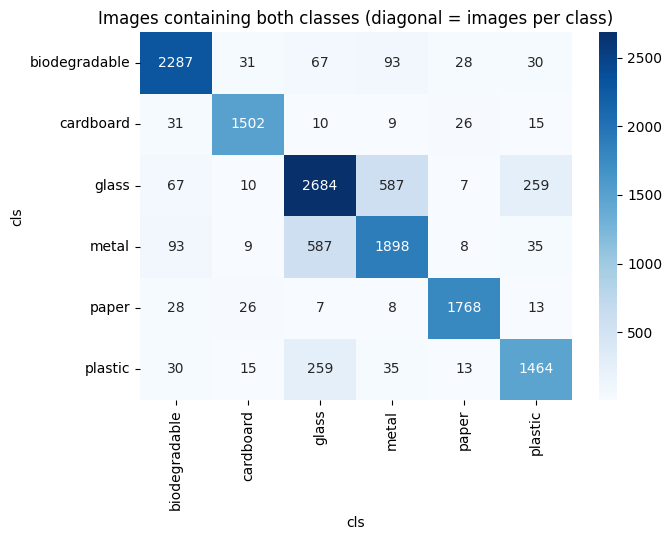

In [ ]:
import seaborn as sns
cls_per_img = ann.groupby("image")["cls"].nunique()
print("Number of distinct classes per image:")
print(cls_per_img.value_counts().sort_index().to_string())

mh = pd.crosstab(ann["image"], ann["cls"]).clip(upper=1)
co = mh.T.dot(mh)
plt.figure(figsize=(7, 5.5))
sns.heatmap(co, annot=True, fmt="d", cmap="Blues", xticklabels=CLASS_NAMES, yticklabels=CLASS_NAMES)
plt.title("Images containing both classes (diagonal = images per class)"); plt.tight_layout(); plt.show()

## 1.9 Box overlap (crowded / occluded scenes)
High IoU between two ground-truth boxes means heavy occlusion or duplicated annotations. This affects NMS (an IoU threshold that is too low removes true neighbours) and the maximum number of detections per image.

In [ ]:
def iou_matrix(b):                      # b: (n,4) xyxy
    x1 = np.maximum(b[:, None, 0], b[None, :, 0]); y1 = np.maximum(b[:, None, 1], b[None, :, 1])
    x2 = np.minimum(b[:, None, 2], b[None, :, 2]); y2 = np.minimum(b[:, None, 3], b[None, :, 3])
    inter = np.clip(x2 - x1, 0, None) * np.clip(y2 - y1, 0, None)
    area = (b[:, 2] - b[:, 0]) * (b[:, 3] - b[:, 1])
    return inter / (area[:, None] + area[None, :] - inter + 1e-12)

n_pairs = n_gt5 = n_gt9 = 0; imgs_gt5 = 0
for _, g in tqdm(ann[~bad_wh].groupby("image"), desc="IoU"):
    if len(g) < 2: continue
    b = np.stack([g.xc - g.w/2, g.yc - g.h/2, g.xc + g.w/2, g.yc + g.h/2], 1)
    iu = np.triu(iou_matrix(b), 1)
    n_pairs += (iu > 0).sum(); n_gt5 += (iu > 0.5).sum(); n_gt9 += (iu > 0.9).sum(); imgs_gt5 += (iu > 0.5).any()
print("Overlapping box pairs (IoU>0):", n_pairs)
print("Pairs with IoU>0.5:", n_gt5, "| in", imgs_gt5, "images")
print("Pairs with IoU>0.9 (likely duplicate annotations):", n_gt9)

IoU:   0%|          | 0/10464 [00:00<?, ?it/s]

Overlapping box pairs (IoU>0): 115492
Pairs with IoU>0.5: 1532 | in 874 images
Pairs with IoU>0.9 (likely duplicate annotations): 56


### Observation: overlapping boxes
- 115,492 overlapping box pairs, **1,532 pairs with IoU > 0.5 in 874 images** (8.4 % of images), and 56 pairs with IoU > 0.9.
- **Consequences:** crowded scenes make NMS and recall harder. Near-identical boxes (IoU > 0.95, same class) are removed as duplicate annotations (20 boxes).

## 1.10 Visual inspection of annotated samples (random + densest image)

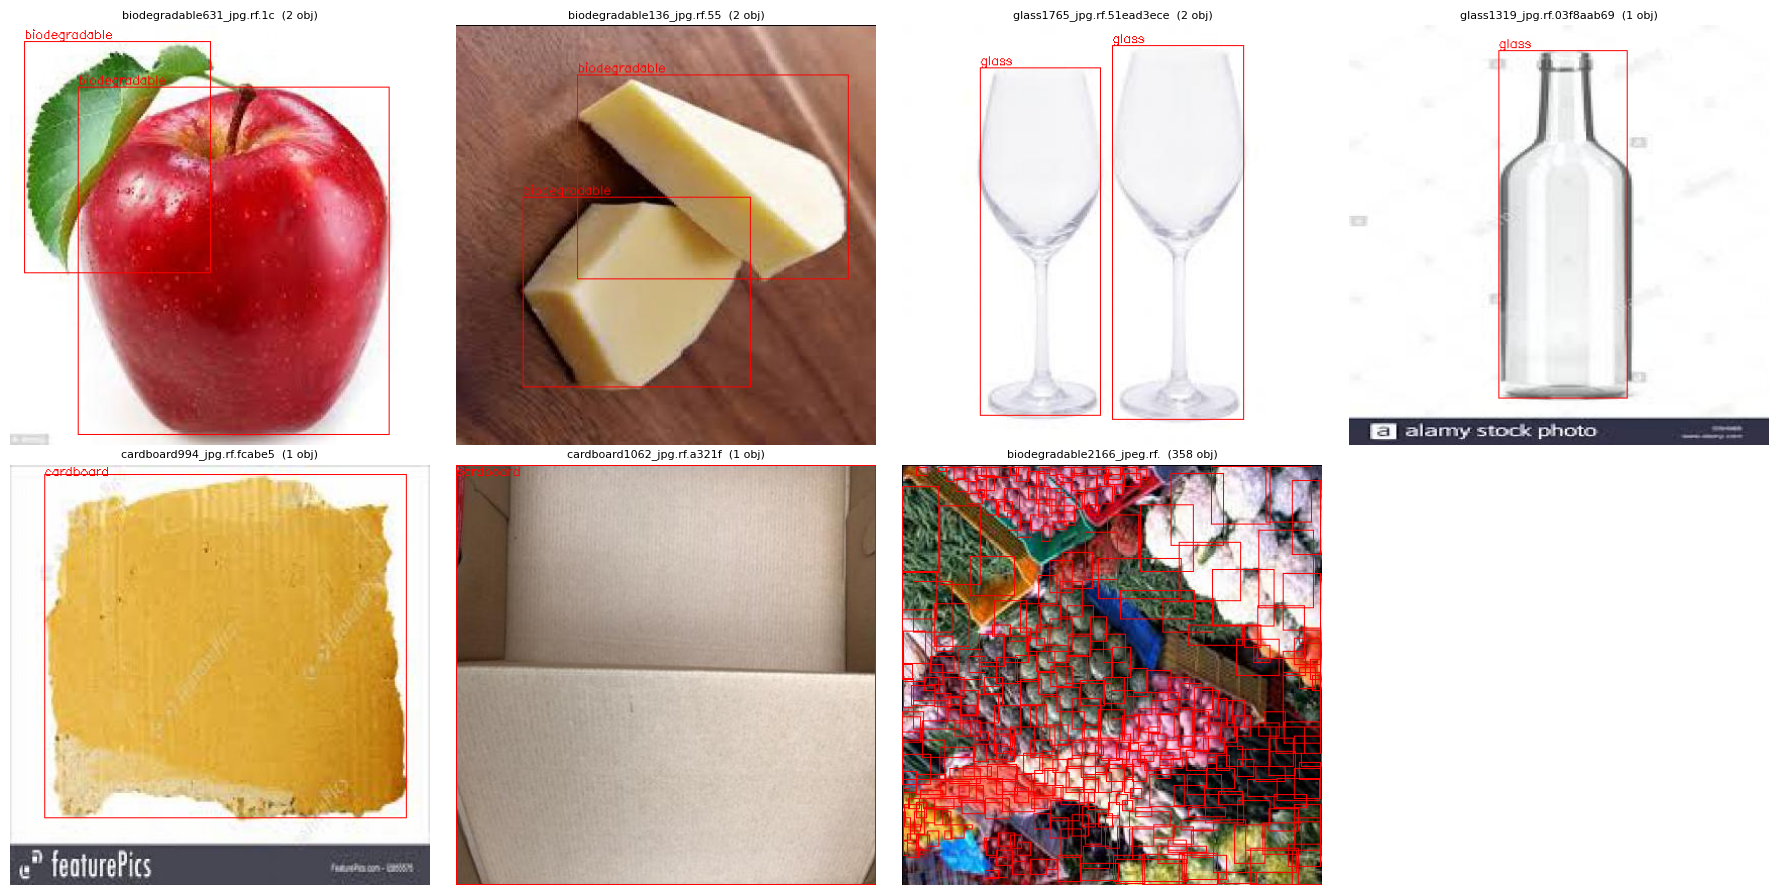

In [ ]:
def draw_gt(path, ax, thickness=1, names=True):
    im = cv2.cvtColor(cv2.imread(str(path)), cv2.COLOR_BGR2RGB)
    h, w = im.shape[:2]
    for _, r in ann[ann["image"] == path.stem].iterrows():
        x1, y1 = int((r.xc - r.w/2) * w), int((r.yc - r.h/2) * h)
        x2, y2 = int((r.xc + r.w/2) * w), int((r.yc + r.h/2) * h)
        cv2.rectangle(im, (x1, y1), (x2, y2), (255, 0, 0), thickness)
        if names: cv2.putText(im, CLASS_NAMES[int(r.cls)], (x1, max(y1 - 3, 10)), cv2.FONT_HERSHEY_SIMPLEX, 0.4, (255, 0, 0), 1)
    ax.imshow(im); ax.axis("off")

rng = random.Random(SEED)
sample = rng.sample(image_files, 6) + [IMG_DIR / f"{objs.idxmax()}.jpg"]
fig, axes = plt.subplots(2, 4, figsize=(18, 9))
for ax, p in zip(axes.flat, sample):
    draw_gt(p, ax, names=(p.stem != objs.idxmax())); ax.set_title(f"{p.name[:26]}  ({objs[p.stem]} obj)", fontsize=8)
axes.flat[-1].axis("off")
plt.tight_layout(); plt.show()

# 2. Duplicate and Near-Duplicate Analysis (Task 1)

If copies of the same photo end up in different splits, the test score is inflated (data leakage).
An exact byte hash (MD5) only finds identical files. Datasets exported from Roboflow (`..._jpg.rf.<hash>.jpg`) often contain **flipped, rotated, re-compressed or brightness-shifted copies** of the same source image, which have different bytes. We therefore use three checks:

1. exact duplicates (MD5),
2. same source name (filename before `.rf.`),
3. **perceptual hash (pHash)** on the image and on its 7 flipped/rotated versions → near-duplicates, also across class prefixes.

## 2.1 Exact duplicates and same-source filenames

In [ ]:
md5 = {}
for p in tqdm(image_files, desc="md5"):
    md5.setdefault(hashlib.md5(p.read_bytes()).hexdigest(), []).append(p.name)
print("Exact duplicate groups (MD5):", sum(len(v) > 1 for v in md5.values()))

def source_key(p): return re.sub(r"\.rf\.[0-9a-f]+$", "", p.stem)
by_src = {}
for p in image_files: by_src.setdefault(source_key(p), []).append(p.name)
print("Source names that appear more than once:", sum(len(v) > 1 for v in by_src.values()))

md5:   0%|          | 0/10464 [00:00<?, ?it/s]

Exact duplicate groups (MD5): 0
Source names that appear more than once: 0


## 2.2 Perceptual hashes (original + 7 flips/rotations per image)

In [ ]:
import imagehash
T = Image.Transpose

def dihedral(im):
    return [im, im.transpose(T.FLIP_LEFT_RIGHT), im.transpose(T.FLIP_TOP_BOTTOM), im.transpose(T.ROTATE_180),
            im.transpose(T.ROTATE_90), im.transpose(T.ROTATE_270), im.transpose(T.TRANSPOSE), im.transpose(T.TRANSVERSE)]

def to_u64(h):
    return np.uint64(int("".join("1" if b else "0" for b in h.hash.flatten()), 2))

HV = np.zeros((len(image_files), 8), dtype=np.uint64)
for i, p in enumerate(tqdm(image_files, desc="pHash")):
    with Image.open(p) as im:
        small = im.convert("L").resize((64, 64), Image.LANCZOS)
    HV[i] = [to_u64(imagehash.phash(v, hash_size=8)) for v in dihedral(small)]
H0 = HV[:, 0].copy()
print("hashes:", HV.shape)

pHash:   0%|          | 0/10464 [00:00<?, ?it/s]

hashes: (10464, 8)


## 2.3 Find near-duplicate pairs (Hamming distance over the 64-bit hash)

In [ ]:
POP = np.array([bin(i).count("1") for i in range(256)], dtype=np.uint8)
def popcount64(x):
    if hasattr(np, "bitwise_count"): return np.bitwise_count(x)
    return POP[np.ascontiguousarray(x).view(np.uint8).reshape(*x.shape, 8)].sum(-1)

MAX_D = 10                       # keep every pair up to this Hamming distance
pairs, CH = [], 128
for s in tqdm(range(0, len(image_files), CH), desc="pairs"):
    e = min(s + CH, len(image_files))
    d = popcount64(H0[s:e, None, None] ^ HV[None, :, :]).min(axis=2)       # best of 8 flips/rotations
    for r in range(e - s):
        i = s + r
        js = np.where(d[r, i + 1:] <= MAX_D)[0] + i + 1
        pairs.extend((i, int(j), int(d[r, j])) for j in js)
pairs = np.array(pairs).reshape(-1, 3)
print("Pairs found:", len(pairs))
for t in [0, 2, 4, 6, 8, 10]:
    print(f"  Hamming <= {t:2d}: {(pairs[:, 2] <= t).sum()} pairs")

pairs:   0%|          | 0/82 [00:00<?, ?it/s]

Pairs found: 7678
  Hamming <=  0: 46 pairs
  Hamming <=  2: 134 pairs
  Hamming <=  4: 289 pairs
  Hamming <=  6: 711 pairs
  Hamming <=  8: 2234 pairs
  Hamming <= 10: 7678 pairs


## 2.4 Choose the threshold by looking at the images
Look at the plots below: top rows (distance ≤ `THRESH`) should be the **same photo**; the borderline pairs (distance 5–10) show what you would additionally merge if you raised the threshold.
If borderline pairs are still the same photo, **raise** `THRESH`; if they are different objects, keep it low.

THRESH=4: 186 duplicate groups, 432 images inside groups, 246 redundant images, largest group = 25


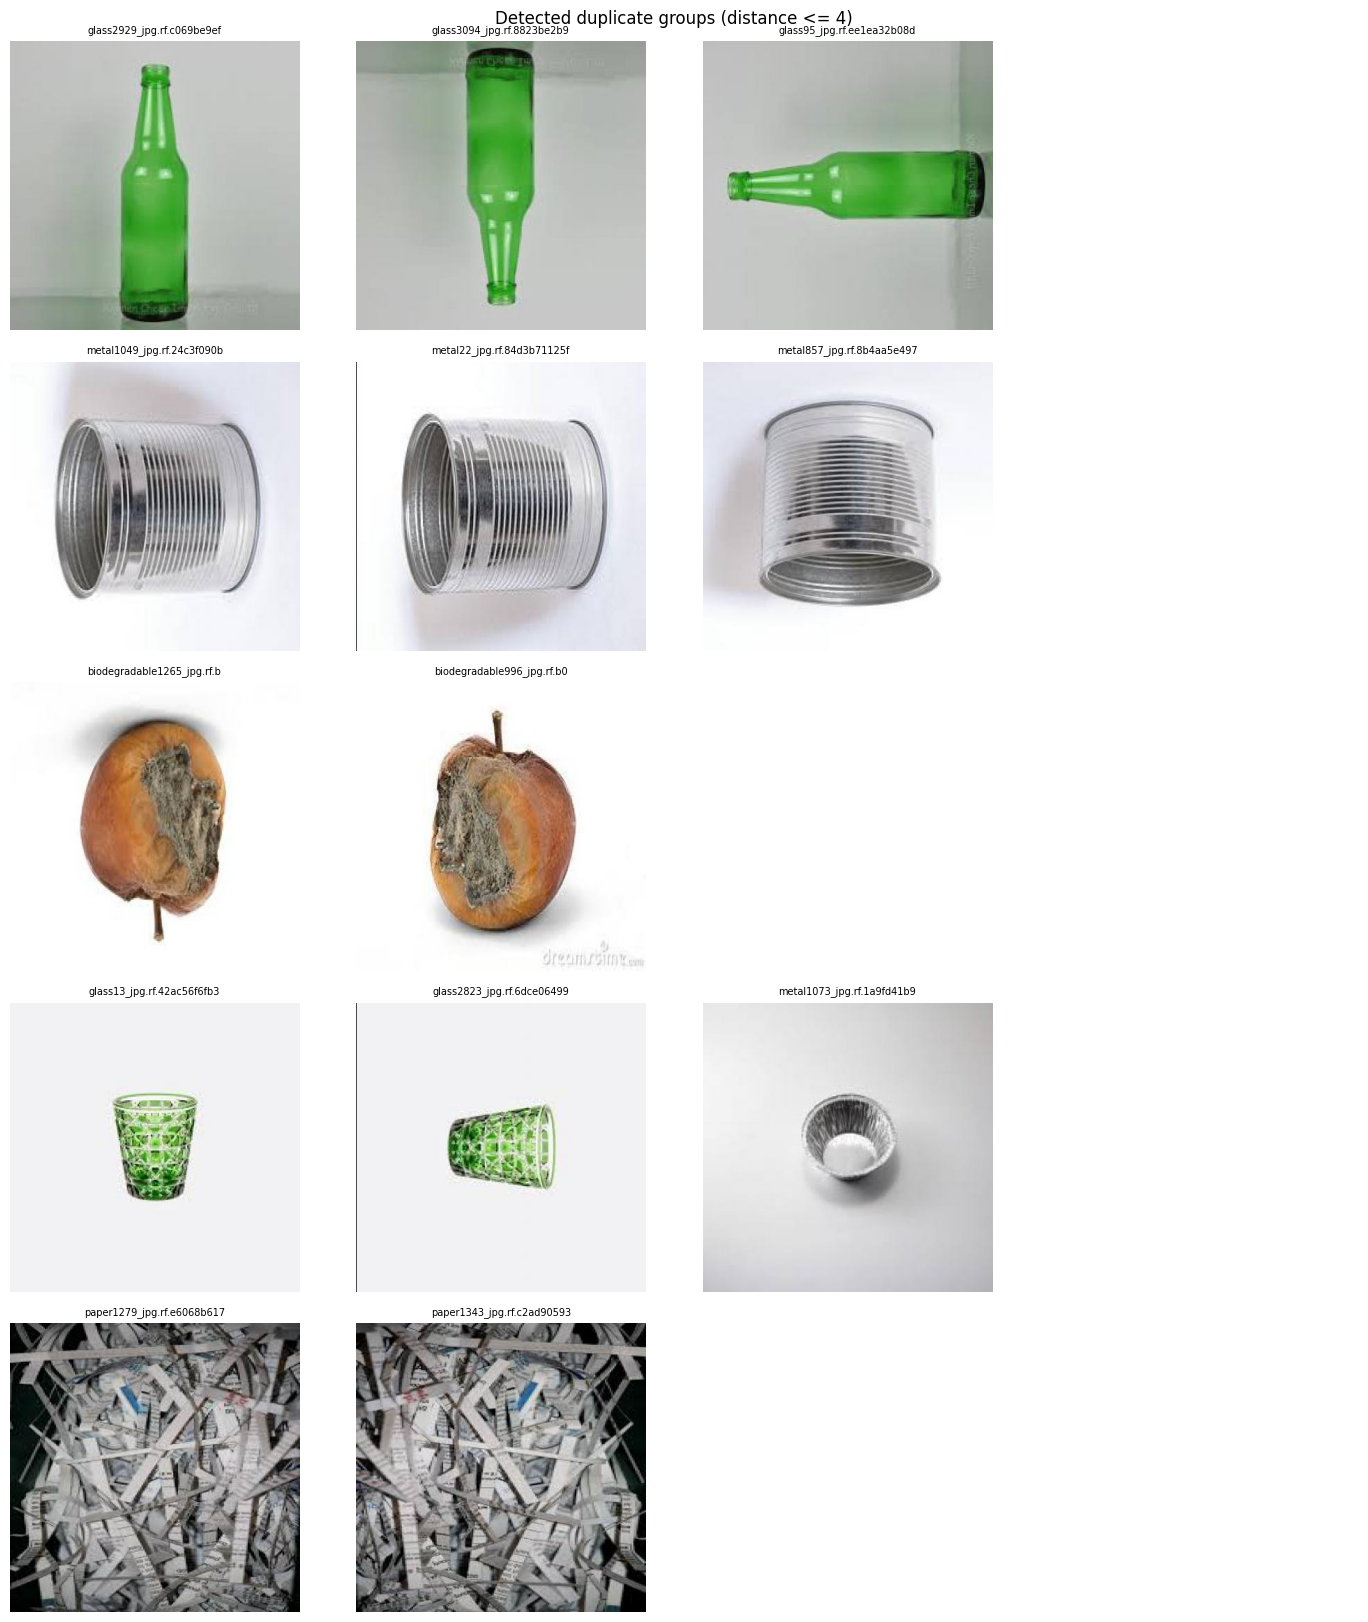

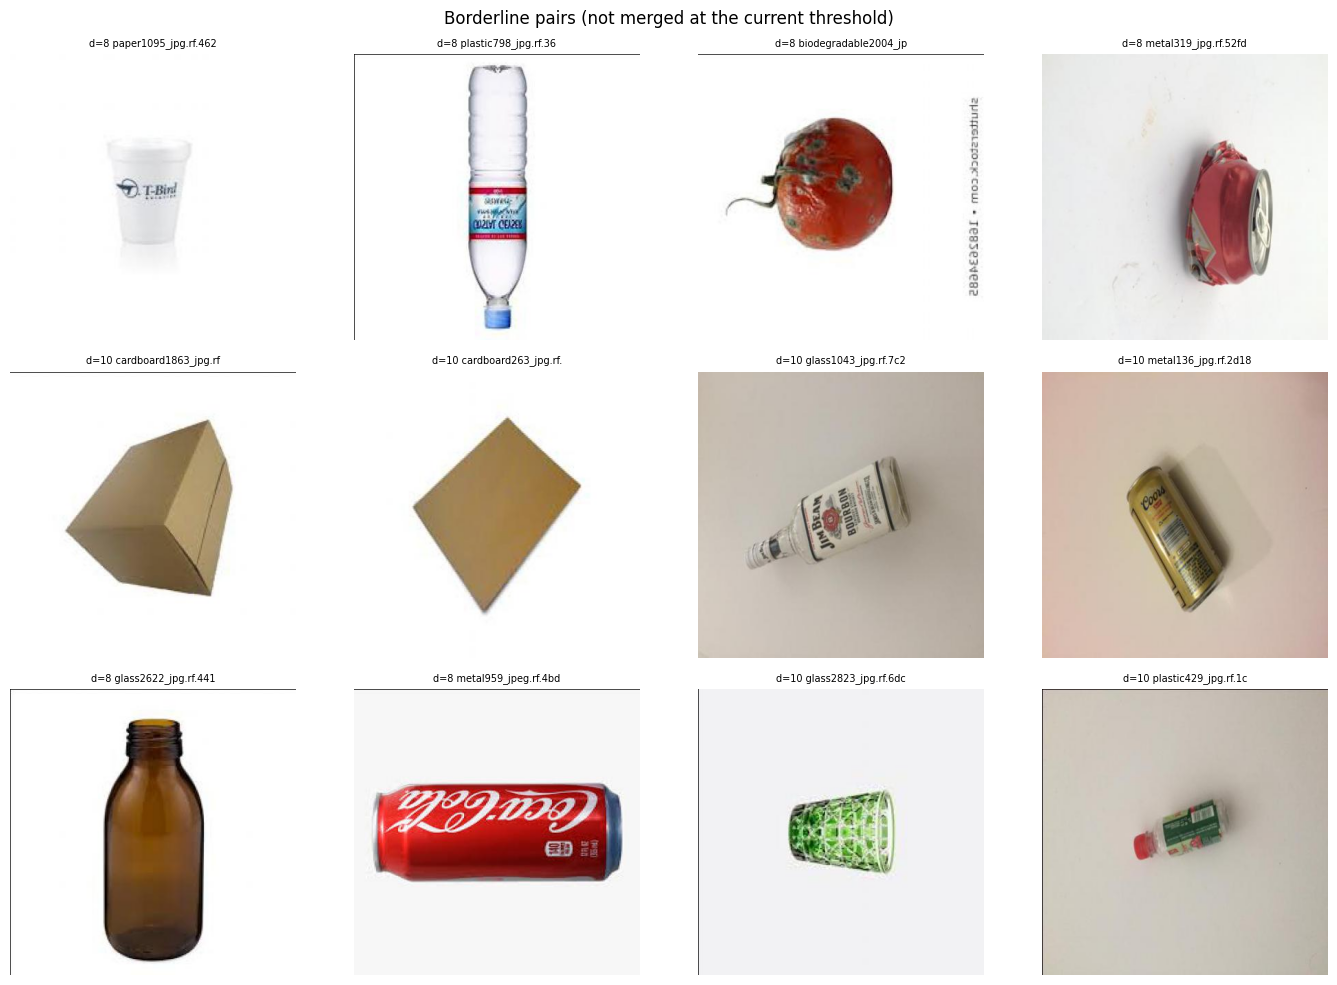

In [ ]:
THRESH = 4

def build_groups(thresh):
    parent = list(range(len(image_files)))
    def find(a):
        while parent[a] != a:
            parent[a] = parent[parent[a]]; a = parent[a]
        return a
    for i, j, d in pairs:
        if d <= thresh: parent[find(i)] = find(j)
    g = {}
    for i in range(len(image_files)): g.setdefault(find(i), []).append(i)
    return list(g.values())

all_groups = build_groups(THRESH)
dup_groups = [g for g in all_groups if len(g) > 1]
print(f"THRESH={THRESH}: {len(dup_groups)} duplicate groups, {sum(map(len, dup_groups))} images inside groups, "
      f"{sum(len(g)-1 for g in dup_groups)} redundant images, largest group = {max(map(len, dup_groups)) if dup_groups else 0}")

rng = random.Random(0)
show = rng.sample(dup_groups, min(5, len(dup_groups)))
fig, axes = plt.subplots(len(show), 4, figsize=(14, 3.3 * max(1, len(show))))
for r, g in enumerate(show):
    for c in range(4):
        ax = np.atleast_2d(axes)[r, c]; ax.axis("off")
        if c < len(g): ax.imshow(Image.open(image_files[g[c]])); ax.set_title(image_files[g[c]].name[:26], fontsize=7)
plt.suptitle(f"Detected duplicate groups (distance <= {THRESH})"); plt.tight_layout(); plt.show()

border = [p for p in pairs if THRESH < p[2] <= MAX_D]
rng.shuffle(border)
fig, axes = plt.subplots(3, 4, figsize=(14, 10))
for k in range(min(6, len(border))):
    i, j, d = border[k]
    for m, idx in enumerate((i, j)):
        ax = axes.flat[2 * k + m]; ax.imshow(Image.open(image_files[idx])); ax.axis("off"); ax.set_title(f"d={d} {image_files[idx].name[:20]}", fontsize=7)
for ax in axes.flat: ax.axis("off")
plt.suptitle("Borderline pairs (not merged at the current threshold)"); plt.tight_layout(); plt.show()

In [ ]:
NCC_T = 0.92          # similarity threshold; lower = more pairs counted as duplicates

S = 32
G = np.zeros((len(image_files), S, S), np.float32)
for i, p in enumerate(tqdm(image_files, desc="thumbnails")):
    with Image.open(p) as im:
        a = np.asarray(im.convert("L").resize((S, S), Image.BILINEAR), dtype=np.float32)
    G[i] = (a - a.mean()) / (a.std() + 1e-6)

def best_ncc(i, j):        # best match over the 8 flips/rotations
    b = G[j]
    return max(float((G[i] * np.rot90(v, k)).mean()) for v in (b, b[:, ::-1]) for k in range(4))

ncc = np.array([best_ncc(i, j) for i, j, d in pairs])

parent = list(range(len(image_files)))
def find(a):
    while parent[a] != a:
        parent[a] = parent[parent[a]]; a = parent[a]
    return a
for (i, j, d), v in zip(pairs, ncc):
    if v >= NCC_T: parent[find(i)] = find(j)

grp = {}
for i in range(len(image_files)): grp.setdefault(find(i), []).append(i)
all_groups = list(grp.values())                       # includes single images (used by the split later)
dup_groups = sorted([g for g in all_groups if len(g) > 1], key=len, reverse=True)
DUP_THRESH = NCC_T

print("Total images                 :", len(image_files))
print("Duplicate groups             :", len(dup_groups))
print("Images inside groups         :", sum(len(g) for g in dup_groups))
print("Redundant copies (extra imgs):", sum(len(g) - 1 for g in dup_groups))
print("Unique images after removal  :", len(image_files) - sum(len(g) - 1 for g in dup_groups))
print("\nGroup size -> number of groups")
print(pd.Series([len(g) for g in dup_groups]).value_counts().sort_index().to_string())

thumbnails:   0%|          | 0/10464 [00:00<?, ?it/s]

Total images                 : 10464
Duplicate groups             : 211
Images inside groups         : 495
Redundant copies (extra imgs): 284
Unique images after removal  : 10180

Group size -> number of groups
2     193
3      14
4       2
5       1
54      1


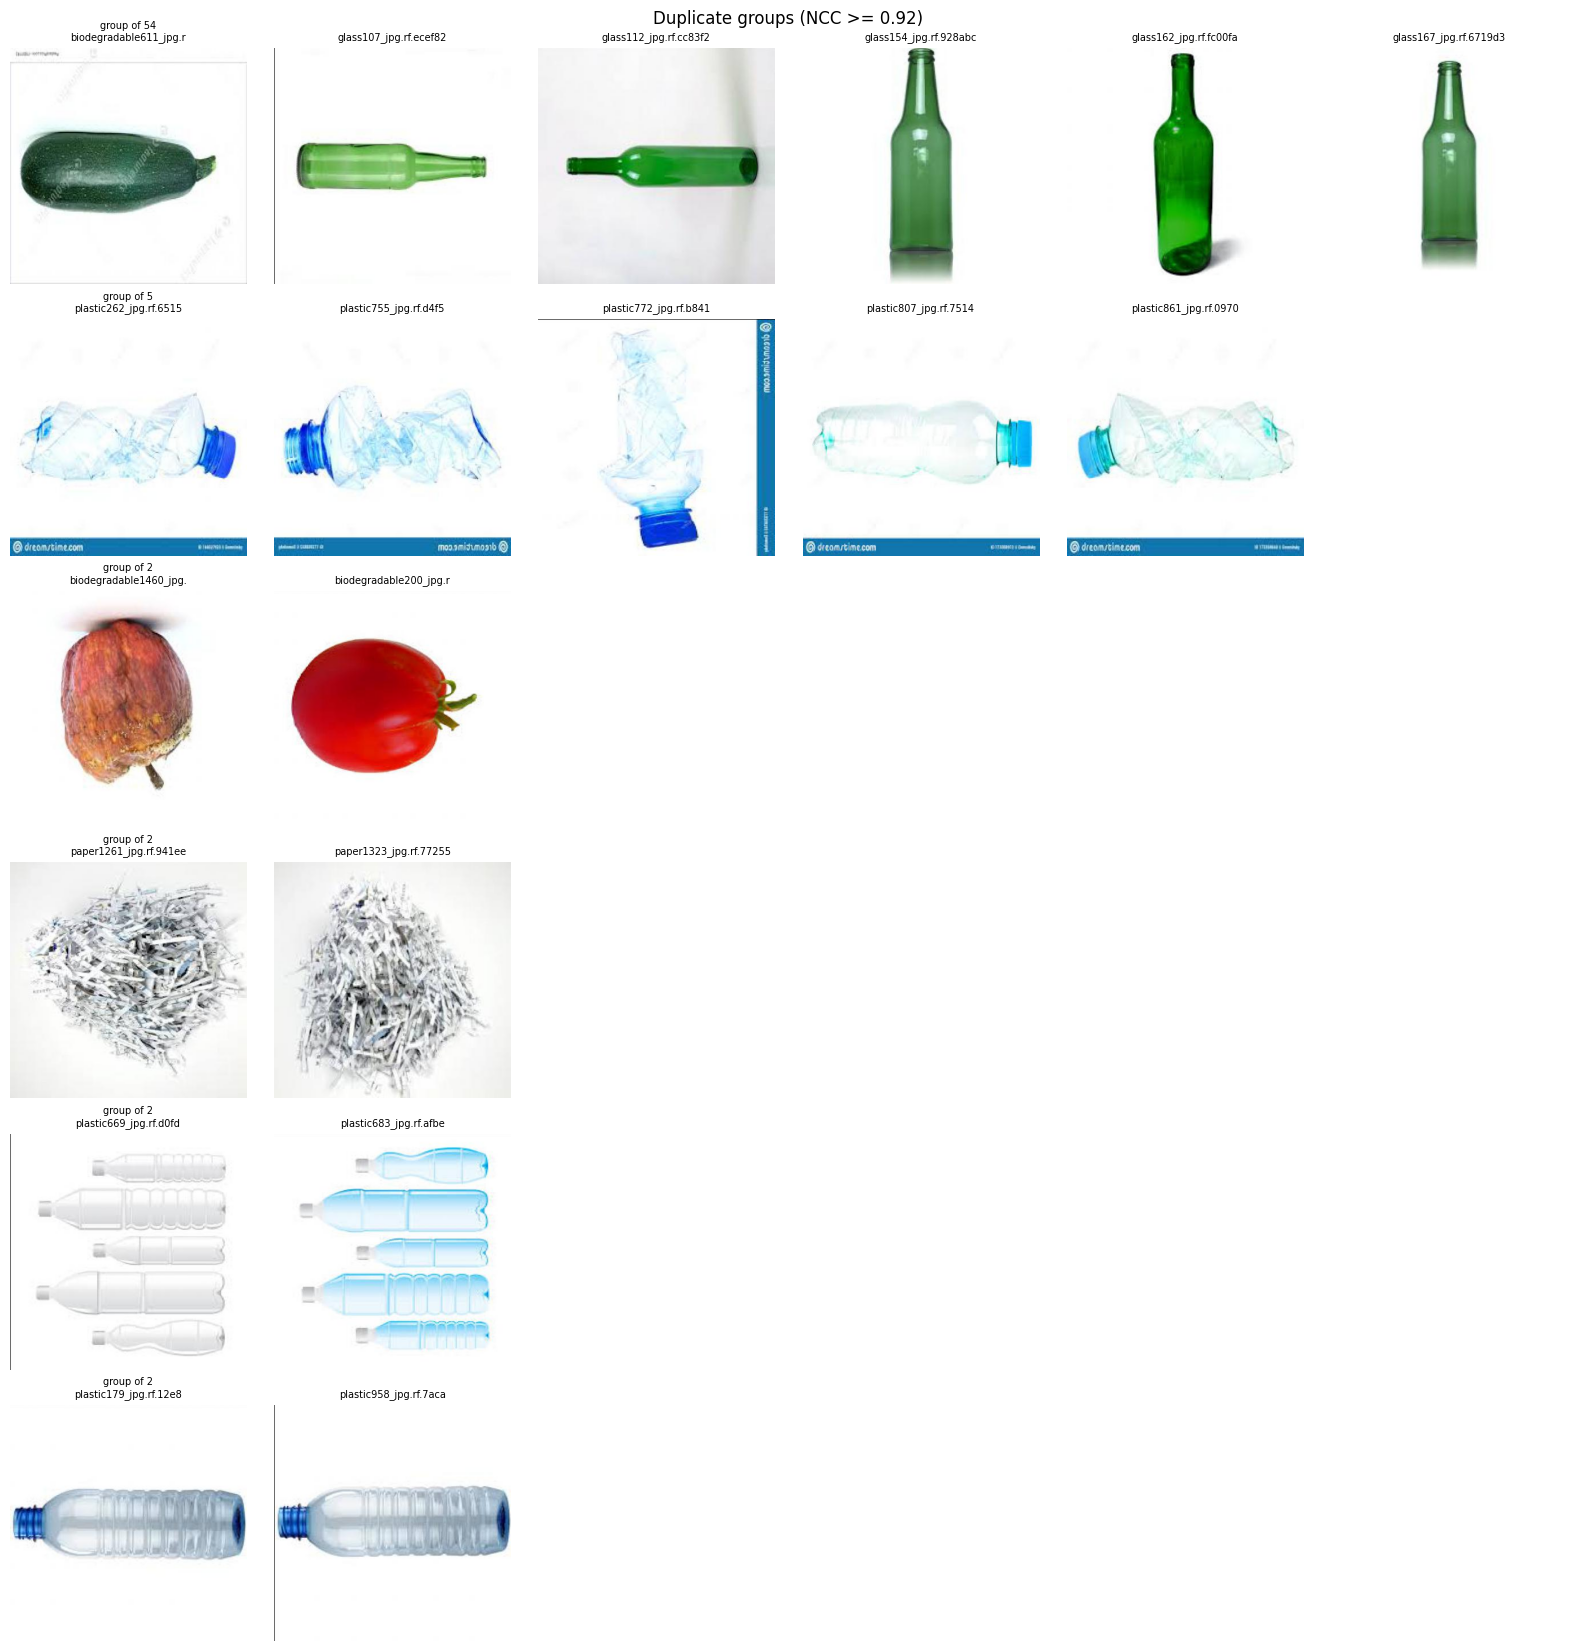

In [ ]:
rng = random.Random(1)
show = dup_groups[:2] + rng.sample(dup_groups[2:], min(4, max(0, len(dup_groups) - 2)))

fig, axes = plt.subplots(len(show), 6, figsize=(16, 2.8 * len(show)))
axes = np.atleast_2d(axes)
for r, g in enumerate(show):
    for c in range(6):
        ax = axes[r, c]; ax.axis("off")
        if c < len(g):
            ax.imshow(Image.open(image_files[g[c]]))
            ax.set_title((f"group of {len(g)}\n" if c == 0 else "") + image_files[g[c]].name[:22], fontsize=7)
plt.suptitle(f"Duplicate groups (NCC >= {NCC_T})"); plt.tight_layout(); plt.show()

In [ ]:
DUP_DIR = PROJECT_DIR / "duplicates"
if DUP_DIR.exists(): shutil.rmtree(DUP_DIR)
DUP_DIR.mkdir(parents=True)

cls_sets = ann.groupby("image")["cls"].apply(lambda s: sorted(set(int(c) for c in s))).to_dict()
rows = []
for gi, g in enumerate(dup_groups):
    gdir = DUP_DIR / f"group_{gi:03d}"; gdir.mkdir()
    for i in g:
        p = image_files[i]
        shutil.copy2(p, gdir / p.name)
        rows.append({"group": gi, "group_size": len(g), "image": p.name, "classes": cls_sets.get(p.stem, [])})

pd.DataFrame(rows).to_csv(DUP_DIR / "duplicate_groups.csv", index=False)
json.dump({"ncc_threshold": NCC_T, "groups": [[image_files[i].name for i in g] for g in dup_groups]},
          open(DUP_DIR / "duplicate_groups.json", "w"), indent=1)

# keep a copy on Google Drive (Colab storage is deleted when the runtime disconnects)
shutil.copytree(DUP_DIR, Path("/content/drive/MyDrive/Portfolio_1_results/duplicates"), dirs_exist_ok=True)
print("Saved", len(rows), "images in", len(dup_groups), "groups to", DUP_DIR)

Saved 495 images in 211 groups to /content/Portfolio_1/duplicates


## 2.5 Do duplicates carry the same labels? Do they cross categories?

In [ ]:
cls_sets = ann.groupby("image")["cls"].apply(lambda s: frozenset(s)).to_dict()
mixed = [g for g in dup_groups if len({cls_sets.get(image_files[i].stem, frozenset()) for i in g}) > 1]
print("Duplicate groups whose images have different class sets:", len(mixed))
prefix_of = lambda i: re.match(r"[a-zA-Z]+", image_files[i].name).group(0).lower()
cross = [g for g in dup_groups if len({prefix_of(i) for i in g}) > 1]
print("Duplicate groups spanning several filename prefixes (same photo under 2 categories):", len(cross))

Duplicate groups whose images have different class sets: 29
Duplicate groups spanning several filename prefixes (same photo under 2 categories): 26


**Decision:** all images of one duplicate group are kept together in the same split (group-aware split, section 3.3). Additionally, validation and test contain one representative per group, so that metrics are not inflated by counting the same photo several times. Training keeps all copies.

In [ ]:
DUP_THRESH = THRESH
json.dump({"threshold": DUP_THRESH, "groups": [[image_files[i].name for i in g] for g in dup_groups]},
          open(PROJECT_DIR / "duplicate_groups.json", "w"), indent=1)
print("saved", PROJECT_DIR / "duplicate_groups.json")

saved /content/Portfolio_1/duplicate_groups.json


### Result: duplicates
| Check | Result |
|---|---|
| Identical files (MD5) | 0 |
| Same source name | 0 |
| Near-duplicates, perceptual hash (Hamming ≤ 4) | **186 groups, 432 images, 246 redundant copies** |
| Near-duplicates, hash + pixel correlation (NCC ≥ 0.92) | 211 groups, 495 images, 284 redundant copies |

- The copies are flipped, rotated or brightness-changed versions of the same photo, so exact-file checks find nothing.
- 26 groups span two filename categories (the same photo filed under two categories), and 29 groups have different class sets.
- The pixel check shows one chained group of 54 images (different photos with plain backgrounds linked through a chain of similar pairs). We treat it as a chaining artefact.

**Decision:** all images of a group stay together in one split, and validation and test keep one image per group, so the test score is not inflated by leaked or double-counted photos.

# 3. Cleaning and Leakage-Free Train / Validation / Test Split (Task 1)

The raw data stays untouched; all changes are written to `data/processed`.

## 3.1 Clean annotations
* remove boxes with zero/negative size or sub-pixel size (< 1 px side),
* clip boxes that slightly leave the image to the image border,
* remove duplicated boxes (same class, IoU > 0.95 in the same image) – the detector cannot learn to output two identical boxes and NMS would suppress one anyway,
* drop images that have no valid box left (they cannot be stratified).

In [ ]:
REMOVE_DUP_BOXES, DUP_BOX_IOU = True, 0.95

clean = ann[["image", "cls", "xc", "yc", "w", "h"]].copy()
n0 = len(clean)

clean = clean[(clean.w * IMGSZ >= 1) & (clean.h * IMGSZ >= 1) & clean.xc.between(0, 1) & clean.yc.between(0, 1)]
n_invalid = n0 - len(clean)

x1 = (clean.xc - clean.w / 2).clip(0, 1); x2 = (clean.xc + clean.w / 2).clip(0, 1)
y1 = (clean.yc - clean.h / 2).clip(0, 1); y2 = (clean.yc + clean.h / 2).clip(0, 1)
clean["xc"], clean["yc"], clean["w"], clean["h"] = (x1 + x2) / 2, (y1 + y2) / 2, x2 - x1, y2 - y1
clean = clean[(clean.w > 0) & (clean.h > 0)]

n_dupbox = 0
if REMOVE_DUP_BOXES:
    keep_idx = []
    for img, g in tqdm(clean.groupby("image"), desc="dup boxes"):
        if len(g) < 2:
            keep_idx.extend(g.index); continue
        b = np.stack([g.xc - g.w/2, g.yc - g.h/2, g.xc + g.w/2, g.yc + g.h/2], 1)
        iu = np.triu(iou_matrix(b), 1) > DUP_BOX_IOU
        same = g["cls"].values[:, None] == g["cls"].values[None, :]
        drop = set(np.where((iu & same).any(axis=0))[0])
        keep_idx.extend(g.index[[k for k in range(len(g)) if k not in drop]])
    n_dupbox = len(clean) - len(keep_idx)
    clean = clean.loc[keep_idx]

clean = clean.sort_index().reset_index(drop=True)
valid_images = sorted(clean["image"].unique())
no_box_images = sorted(set(all_images) - set(valid_images))
print(f"Original boxes: {n0}")
print(f"  removed invalid / sub-pixel : {n_invalid}")
print(f"  removed duplicate boxes     : {n_dupbox}")
print(f"Remaining boxes: {len(clean)}")
print(f"Images dropped (no valid box left): {len(no_box_images)}  {no_box_images[:5]}")
print(f"Images kept: {len(valid_images)}")

dup boxes:   0%|          | 0/10464 [00:00<?, ?it/s]

Original boxes: 74090
  removed invalid / sub-pixel : 17
  removed duplicate boxes     : 20
Remaining boxes: 74053
Images dropped (no valid box left): 0  []
Images kept: 10464


In [ ]:
all_groups = build_groups(THRESH)
dup_groups = [g for g in all_groups if len(g) > 1]
print(len(all_groups), "split units;", len(dup_groups), "duplicate groups")   # expect 10218 and 186

10218 split units; 186 duplicate groups


## 3.2 Multi-label matrix per image and per duplicate group
An image can contain several classes, so ordinary stratification on one label is wrong. We use **iterative multi-label stratification** (Sechidis et al., 2011). To avoid leakage it is applied to **duplicate groups** (all near-duplicates form one unit), where the label vector of a group is the union of the class sets of its members.

In [ ]:
name_to_idx = {p.stem: i for i, p in enumerate(image_files)}
group_of = {}                                  # image stem -> group id
for gid, g in enumerate(all_groups):           # all_groups includes singletons
    for i in g: group_of[image_files[i].stem] = gid

mh_img = pd.crosstab(clean["image"], clean["cls"]).reindex(columns=range(NC), fill_value=0).clip(upper=1)
mh_img["gid"] = [group_of[n] for n in mh_img.index]
mh_grp = mh_img.groupby("gid").max()           # union of classes inside each group
print("Images:", len(mh_img), "| groups (split units):", len(mh_grp))

Images: 10464 | groups (split units): 10218


## 3.3 Group-aware, multi-label stratified split: 70 % train / 20 % validation / 10 % test

In [ ]:
from iterstrat.ml_stratifiers import MultilabelStratifiedShuffleSplit

gids = mh_grp.index.to_numpy()
Yg   = mh_grp[list(range(NC))].to_numpy()

s1 = MultilabelStratifiedShuffleSplit(n_splits=1, test_size=0.10, random_state=SEED)
dev_i, test_i = next(s1.split(np.zeros(len(gids)), Yg))
s2 = MultilabelStratifiedShuffleSplit(n_splits=1, test_size=2/9, random_state=SEED)
tr_rel, va_rel = next(s2.split(np.zeros(len(dev_i)), Yg[dev_i]))
train_g, val_g, test_g = set(gids[dev_i[tr_rel]]), set(gids[dev_i[va_rel]]), set(gids[test_i])

split_of = {}
for n, gid in zip(mh_img.index, mh_img["gid"]):
    split_of[n] = "train" if gid in train_g else "val" if gid in val_g else "test"

DEDUP_EVAL = True
if DEDUP_EVAL:
    seen = set()
    for n in sorted(split_of):
        if split_of[n] in ("val", "test"):
            gid = group_of[n]
            if gid in seen: split_of[n] = None
            else: seen.add(gid)
splits = {s: sorted(n for n, v in split_of.items() if v == s) for s in ("train", "val", "test")}
print({k: len(v) for k, v in splits.items()}, "| removed duplicates from val/test:", sum(v is None for v in split_of.values()))

{'train': 7331, 'val': 2022, 'test': 1029} | removed duplicates from val/test: 82


## 3.4 Verify: split sizes, class balance, leakage

,images,biodegradable_boxes,cardboard_boxes,glass_boxes,metal_boxes,paper_boxes,plastic_boxes,images_%
split,,,,,,,,
train,7331,32243,3228,5377,3925,3020,4233,70.6
val,2022,8311,942,1497,1272,776,975,19.5
test,1029,4709,484,689,605,524,691,9.9


Share of boxes per class in every split (%) – should be similar:


cls,biodegradable,cardboard,glass,metal,paper,plastic
split,,,,,,
test,61.1,6.3,8.9,7.9,6.8,9.0
train,62.0,6.2,10.3,7.5,5.8,8.1
val,60.3,6.8,10.9,9.2,5.6,7.1


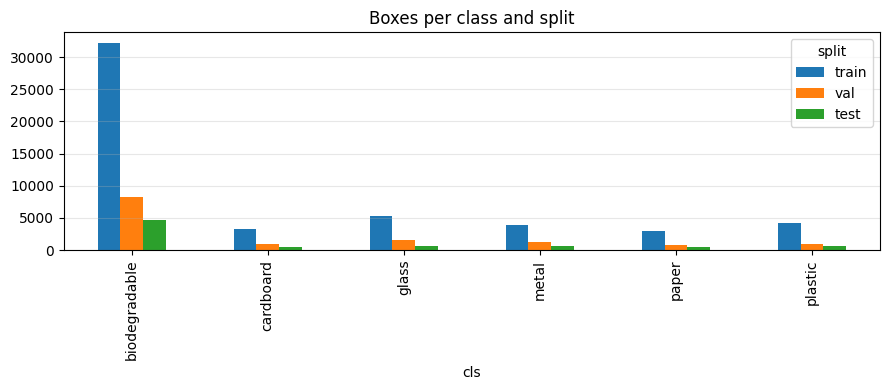

Cross-split near-duplicate pairs with Hamming <=  4: 0
Cross-split near-duplicate pairs with Hamming <= 10: 2824
(0 at the chosen threshold is guaranteed by the group split; a non-zero value at 10 shows residual risk from borderline pairs.)


In [ ]:
lab = clean.assign(split=clean["image"].map(split_of)).dropna(subset=["split"])
tab = pd.DataFrame({
    "images": lab.groupby("split")["image"].nunique(),
    **{f"{CLASS_NAMES[c]}_boxes": lab[lab.cls == c].groupby("split").size() for c in range(NC)}}).reindex(["train", "val", "test"])
tab["images_%"] = (tab["images"] / tab["images"].sum() * 100).round(1)
display(tab)

share = (pd.crosstab(lab["split"], lab["cls"].map(dict(enumerate(CLASS_NAMES))), normalize="index") * 100).round(1)
print("Share of boxes per class in every split (%) – should be similar:")
display(share)

fig, ax = plt.subplots(figsize=(9, 4))
(pd.crosstab(lab["split"], lab["cls"].map(dict(enumerate(CLASS_NAMES)))).reindex(["train", "val", "test"])).T.plot.bar(ax=ax)
ax.set_title("Boxes per class and split"); ax.grid(axis="y", alpha=.3); plt.tight_layout(); plt.show()

# leakage check with the perceptual hashes (also pairs between THRESH and MAX_D that were NOT merged)
img_split = {name_to_idx[n]: s for n, s in split_of.items() if s}
for lim in (DUP_THRESH, MAX_D):
    leaks = sum(1 for i, j, d in pairs if d <= lim and i in img_split and j in img_split and img_split[i] != img_split[j])
    print(f"Cross-split near-duplicate pairs with Hamming <= {lim:2d}: {leaks}")
print("(0 at the chosen threshold is guaranteed by the group split; a non-zero value at 10 shows residual risk from borderline pairs.)")

### Result: split
- **Train 7,331 / Val 2,022 / Test 1,029** images (70.6 / 19.5 / 9.9 %). 82 redundant copies were dropped from val and test.
- Class shares are nearly identical across splits (`biodegradable` 62.0 / 60.3 / 61.1 %), so the evaluation is representative.
- Splitting uses **multi-label iterative stratification on duplicate groups**, with a fixed seed (42).

In [ ]:
for thr in (0.92, 0.95):
    cross = [(i, j) for (i, j, d), v in zip(pairs, ncc) if v >= thr and i in img_split and j in img_split and img_split[i] != img_split[j]]
    print(f"NCC >= {thr}: {len(cross)} verified near-duplicate pairs lie in different splits")
    if cross: print(pd.Series([f"{img_split[i]} vs {img_split[j]}" for i, j in cross]).value_counts().to_string())

NCC >= 0.92: 53 verified near-duplicate pairs lie in different splits
val vs train     23
train vs val     13
test vs train     8
train vs test     7
test vs val       2
NCC >= 0.95: 14 verified near-duplicate pairs lie in different splits
val vs train     5
train vs val     5
test vs train    2
train vs test    2


## 3.5 Write the processed dataset (cleaned labels, copies of images) and `data.yaml`

In [ ]:
import yaml
if PROC_DIR.exists(): shutil.rmtree(PROC_DIR)
by_img = {k: g for k, g in clean.groupby("image")}
for s, names in splits.items():
    (PROC_DIR / s / "images").mkdir(parents=True, exist_ok=True)
    (PROC_DIR / s / "labels").mkdir(parents=True, exist_ok=True)
    for n in tqdm(names, desc=s):
        shutil.copy2(IMG_DIR / f"{n}.jpg", PROC_DIR / s / "images" / f"{n}.jpg")
        g = by_img[n]
        (PROC_DIR / s / "labels" / f"{n}.txt").write_text(
            "\n".join(f"{int(r.cls)} {r.xc:.6f} {r.yc:.6f} {r.w:.6f} {r.h:.6f}" for r in g.itertuples()) + "\n")

DATA_YAML = PROC_DIR / "data.yaml"
yaml.safe_dump({"path": str(PROC_DIR), "train": "train/images", "val": "val/images", "test": "test/images",
                "nc": NC, "names": dict(enumerate(CLASS_NAMES))}, open(DATA_YAML, "w"), sort_keys=False)

for s in splits:
    ni, nl = len(list((PROC_DIR / s / "images").glob("*.jpg"))), len(list((PROC_DIR / s / "labels").glob("*.txt")))
    print(f"{s:5s}: {ni} images, {nl} label files")
print(open(DATA_YAML).read())

train:   0%|          | 0/7331 [00:00<?, ?it/s]

val:   0%|          | 0/2022 [00:00<?, ?it/s]

test:   0%|          | 0/1029 [00:00<?, ?it/s]

train: 7331 images, 7331 label files
val  : 2022 images, 2022 label files
test : 1029 images, 1029 label files
path: /content/Portfolio_1/data/processed/GarbageDataset
train: train/images
val: val/images
test: test/images
nc: 6
names:
  0: biodegradable
  1: cardboard
  2: glass
  3: metal
  4: paper
  5: plastic



## 3.6 Dataset findings → design decisions



| Observation | Consequence for the pipeline |
|---|---|
| 61 % of all boxes are `biodegradable`, but only ~22 % of images contain it (many tiny objects per image) | Report **per-class** AP/recall, not only overall; multi-label stratified split so every class is in every split; no class re-weighting that would distort the box-level distribution (discussed as improvement) |
| ~50 % of images have a single object, but some have > 300 objects | Raise `max_det` (default 300) for validation/prediction; use mosaic augmentation to vary object density |
| Median box is ~2 % of the image; `biodegradable` boxes are mostly < 32 px | Small-object problem → keep native 416 px at least, mosaic + scale augmentation; evaluate recall by object size; higher `imgsz` as improvement |
| 1,066 images contain 2+ classes (glass+metal, glass+plastic most frequent) | Multi-label stratification, not single-label |
| Class IDs are not named, 17 boxes invalid, some duplicate boxes (IoU > 0.9) | Cleaning step; names inferred from filename prefix (check 1.7) |
| Exact duplicates: none, but near-duplicates found with perceptual hashing (section 2) | Group-aware split, deduplicated val/test |
| High box overlap (up to IoU 0.99) | NMS IoU threshold matters; some FP/FN are annotation artefacts |

# 4. Training Pipeline (Task 1 → Task 2)

## 4.1 Pipeline design and justification

| Component | Choice | Justification |
|---|---|---|
| Detector | **YOLOv5s** (`yolov5su.pt`, anchor-free head in Ultralytics) | one-stage, real-time, small (9 M parameters), COCO-pretrained → transfer learning on 7 k images converges fast |
| Split | 70/20/10, group-aware, multi-label stratified | no leakage via near-duplicates; all classes in all splits; test set only used once at the end |
| Input size | 416 px (native) | images are 416×416; up-scaling would add compute without new information (try 640 as improvement for small objects) |
| Pre-processing | letterbox/normalisation of Ultralytics, cleaned labels | valid boxes only |
| Augmentation | mosaic (off for last 10 epochs), HSV jitter, horizontal flip, scale ±50 %, translate 10 %, small rotation, random erasing, RandAugment | waste appears in any position/scale/lighting; mosaic raises object density and helps small objects; **no vertical flip** (scenes have gravity: bottles lying on a table); `close_mosaic` removes the train/test distribution gap at the end |
| Optimiser | SGD, lr 0.01 → 0.0001 cosine, momentum 0.937, weight decay 5e-4, 3 warm-up epochs | standard, reproducible YOLO recipe; cosine decay gives a stable final epochs |
| Batch / epochs | 16 / up to 100, early stopping patience 20 | fits a T4; early stopping on validation mAP50-95 prevents over-fitting |
| Mixed precision | AMP | ~2× faster on T4 |
| Model selection | `best.pt` = best validation fitness (0.1 mAP50 + 0.9 mAP50-95) | selection on **validation**, never on test |
| Reproducibility | `seed=42`, `deterministic=True` | repeatable runs |

## 4.2 Load the pretrained model

In [ ]:
from ultralytics import YOLO
model = YOLO("yolov5su.pt")
print("loaded YOLOv5s, classes in the pretrained head:", len(model.names), "(replaced by 6 during training)")

loaded YOLOv5s, classes in the pretrained head: 80 (replaced by 6 during training)


## 4.3 Train


In [ ]:
RUN_NAME = "yolov5s_garbage"
train_results = model.train(
    data=str(DATA_YAML),
    epochs=100, patience=20, batch=16, imgsz=IMGSZ, device=DEVICE, workers=2, cache="ram",
    pretrained=True,
    optimizer="SGD", lr0=0.01, lrf=0.01, cos_lr=True, momentum=0.937, weight_decay=5e-4,
    warmup_epochs=3, amp=True,
    # augmentation
    mosaic=1.0, close_mosaic=10, mixup=0.0,
    hsv_h=0.015, hsv_s=0.5, hsv_v=0.3,
    degrees=5, translate=0.1, scale=0.5, fliplr=0.5, flipud=0.0, erasing=0.4,
    # many objects per image -> allow more detections during validation
    max_det=500,
    seed=SEED, deterministic=True, plots=True, save=True, save_period=10,
    project=str(RUNS_DIR), name=RUN_NAME, exist_ok=True,
)
SAVE_DIR = Path(model.trainer.save_dir)
BEST_PT  = SAVE_DIR / "weights" / "best.pt"
print("run folder :", SAVE_DIR)
print("best model :", BEST_PT, BEST_PT.exists())

Ultralytics 8.4.213 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=ram, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=True, cutmix=0.0, data=/content/Portfolio_1/data/processed/GarbageDataset/data.yaml, degrees=5, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=100, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.5, hsv_v=0.3, imgsz=416, iou=None, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=500, mixup=0.0, mode=train, model=yolov5su.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=yolov5s_garbage, nbs=64, nms=No

In [ ]:
# RUN_NAME = "yolov5s_garbage"
# SAVE_DIR = RUNS_DIR / RUN_NAME; BEST_PT = SAVE_DIR / "weights" / "best.pt"
# model = YOLO(str(SAVE_DIR / "weights" / "last.pt")); model.train(resume=True)

## 4.4 Training curves (own plot from `results.csv`)

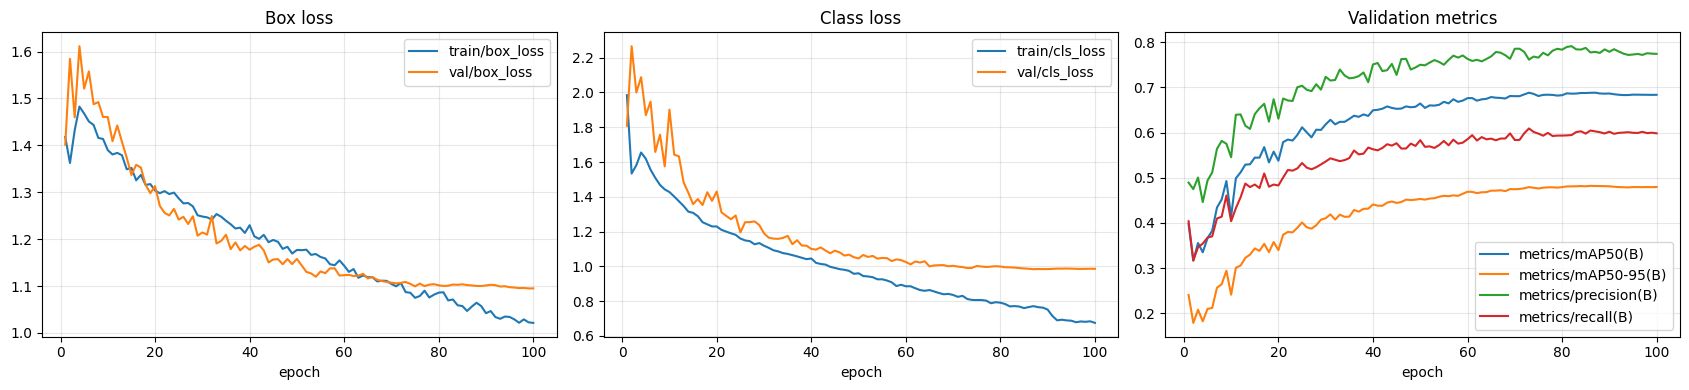

Best epoch: 86 | val mAP50=0.688 | val mAP50-95=0.482
Epochs trained: 100


In [ ]:
res = pd.read_csv(SAVE_DIR / "results.csv"); res.columns = [c.strip() for c in res.columns]
fig, ax = plt.subplots(1, 3, figsize=(17, 4))
for k in ["train/box_loss", "val/box_loss"]: ax[0].plot(res["epoch"], res[k], label=k)
for k in ["train/cls_loss", "val/cls_loss"]: ax[1].plot(res["epoch"], res[k], label=k)
for k in ["metrics/mAP50(B)", "metrics/mAP50-95(B)", "metrics/precision(B)", "metrics/recall(B)"]: ax[2].plot(res["epoch"], res[k], label=k)
for a, t in zip(ax, ["Box loss", "Class loss", "Validation metrics"]): a.set_title(t); a.set_xlabel("epoch"); a.legend(); a.grid(alpha=.3)
plt.tight_layout(); plt.show()
bi = res["metrics/mAP50-95(B)"].idxmax()
print(f"Best epoch: {int(res.loc[bi, 'epoch'])} | val mAP50={res.loc[bi, 'metrics/mAP50(B)']:.3f} | val mAP50-95={res.loc[bi, 'metrics/mAP50-95(B)']:.3f}")
print("Epochs trained:", len(res))

### Training summary
- 100 epochs in **2.17 h** on a Tesla T4. Early stopping (patience 20) never triggered, so the model was still improving slowly.
- Best epoch: **86**, with validation mAP50 = **0.688** and mAP50-95 = **0.482**.
- Train and validation losses fall together, so there is no strong over-fitting.

# 5. Evaluation on the Test Set (Task 2)

The test set was not used for training, augmentation choices or model selection.
Metrics: **Precision, Recall, mAP@0.5, mAP@0.5:0.95** (per class and overall), confusion matrix, PR curves.
mAP is computed by Ultralytics at a very low confidence (0.001) over all thresholds; this is the standard way and independent of one particular threshold.

In [ ]:
best = YOLO(str(BEST_PT))
EVAL_KW = dict(data=str(DATA_YAML), imgsz=IMGSZ, batch=16, device=DEVICE, max_det=500, plots=True, project=str(RUNS_DIR), exist_ok=True)
val_m  = best.val(split="val",  name="eval_val",  **EVAL_KW)
test_m = best.val(split="test", name="eval_test", **EVAL_KW)
TEST_DIR = Path(test_m.save_dir)

Ultralytics 8.4.213 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
YOLOv5s summary (fused): 84 layers, 9,113,858 parameters, 0 gradients, 23.8 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 676.5±310.2 MB/s, size: 22.8 KB)
val: Scanning /content/Portfolio_1/data/processed/GarbageDataset/val/labels.cache... 2022 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 2022/2022 72.5Mit/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 127/127 7.1it/s 18.0s
                   all       2022      13773      0.778      0.604      0.688      0.482
         biodegradable        452       8311      0.806      0.539      0.653      0.361
             cardboard        297        942       0.69      0.461      0.561      0.404
                 glass        519       1497      0.798      0.728      0.806      0.592
                 metal        369       1272      0.816      0.598      0.662       0.47
        

## 5.1 Per-class metrics (validation vs. test)

In [ ]:
def metrics_table(m, split):
    rows = []
    for k, ci in enumerate(m.box.ap_class_index):
        p, r, ap50, ap = m.box.class_result(k)
        rows.append({"class": m.names[int(ci)], "P": p, "R": r, "F1": 2*p*r/(p+r+1e-9), "AP50": ap50, "AP50-95": ap})
    df = pd.DataFrame(rows).set_index("class")
    df.loc["ALL"] = [m.box.mp, m.box.mr, 2*m.box.mp*m.box.mr/(m.box.mp+m.box.mr+1e-9), m.box.map50, m.box.map]
    return df.round(3).add_suffix(f" ({split})")

tab_val, tab_test = metrics_table(val_m, "val"), metrics_table(test_m, "test")
test_lab = clean[clean["image"].map(split_of) == "test"]
inst = test_lab["cls"].map(dict(enumerate(CLASS_NAMES))).value_counts()
final = tab_test.join(tab_val[["AP50 (val)", "AP50-95 (val)"]])
final.insert(0, "test boxes", [inst.get(i, int(inst.sum())) for i in final.index])
display(final)
print("Speed per image (ms):", {k: round(v, 2) for k, v in test_m.speed.items()})
print("Parameters (fused):", sum(p.numel() for p in best.model.parameters()))

,test boxes,P (test),R (test),F1 (test),AP50 (test),AP50-95 (test),AP50 (val),AP50-95 (val)
class,,,,,,,,
biodegradable,4709,0.711,0.541,0.614,0.602,0.330,0.653,0.361
cardboard,484,0.657,0.583,0.618,0.645,0.463,0.561,0.404
glass,689,0.809,0.808,0.809,0.869,0.672,0.806,0.592
metal,605,0.767,0.702,0.733,0.755,0.524,0.662,0.470
paper,524,0.775,0.512,0.617,0.613,0.453,0.741,0.561
plastic,691,0.769,0.520,0.620,0.643,0.423,0.708,0.505
ALL,7702,0.748,0.611,0.673,0.688,0.478,0.688,0.482


Speed per image (ms): {'preprocess': 0.68, 'inference': 3.29, 'loss': 0.0, 'postprocess': 1.82}
Parameters (fused): 9124514


## 5.2 Confusion matrix and PR / F1 curves (test set)

confusion_matrix_normalized.png


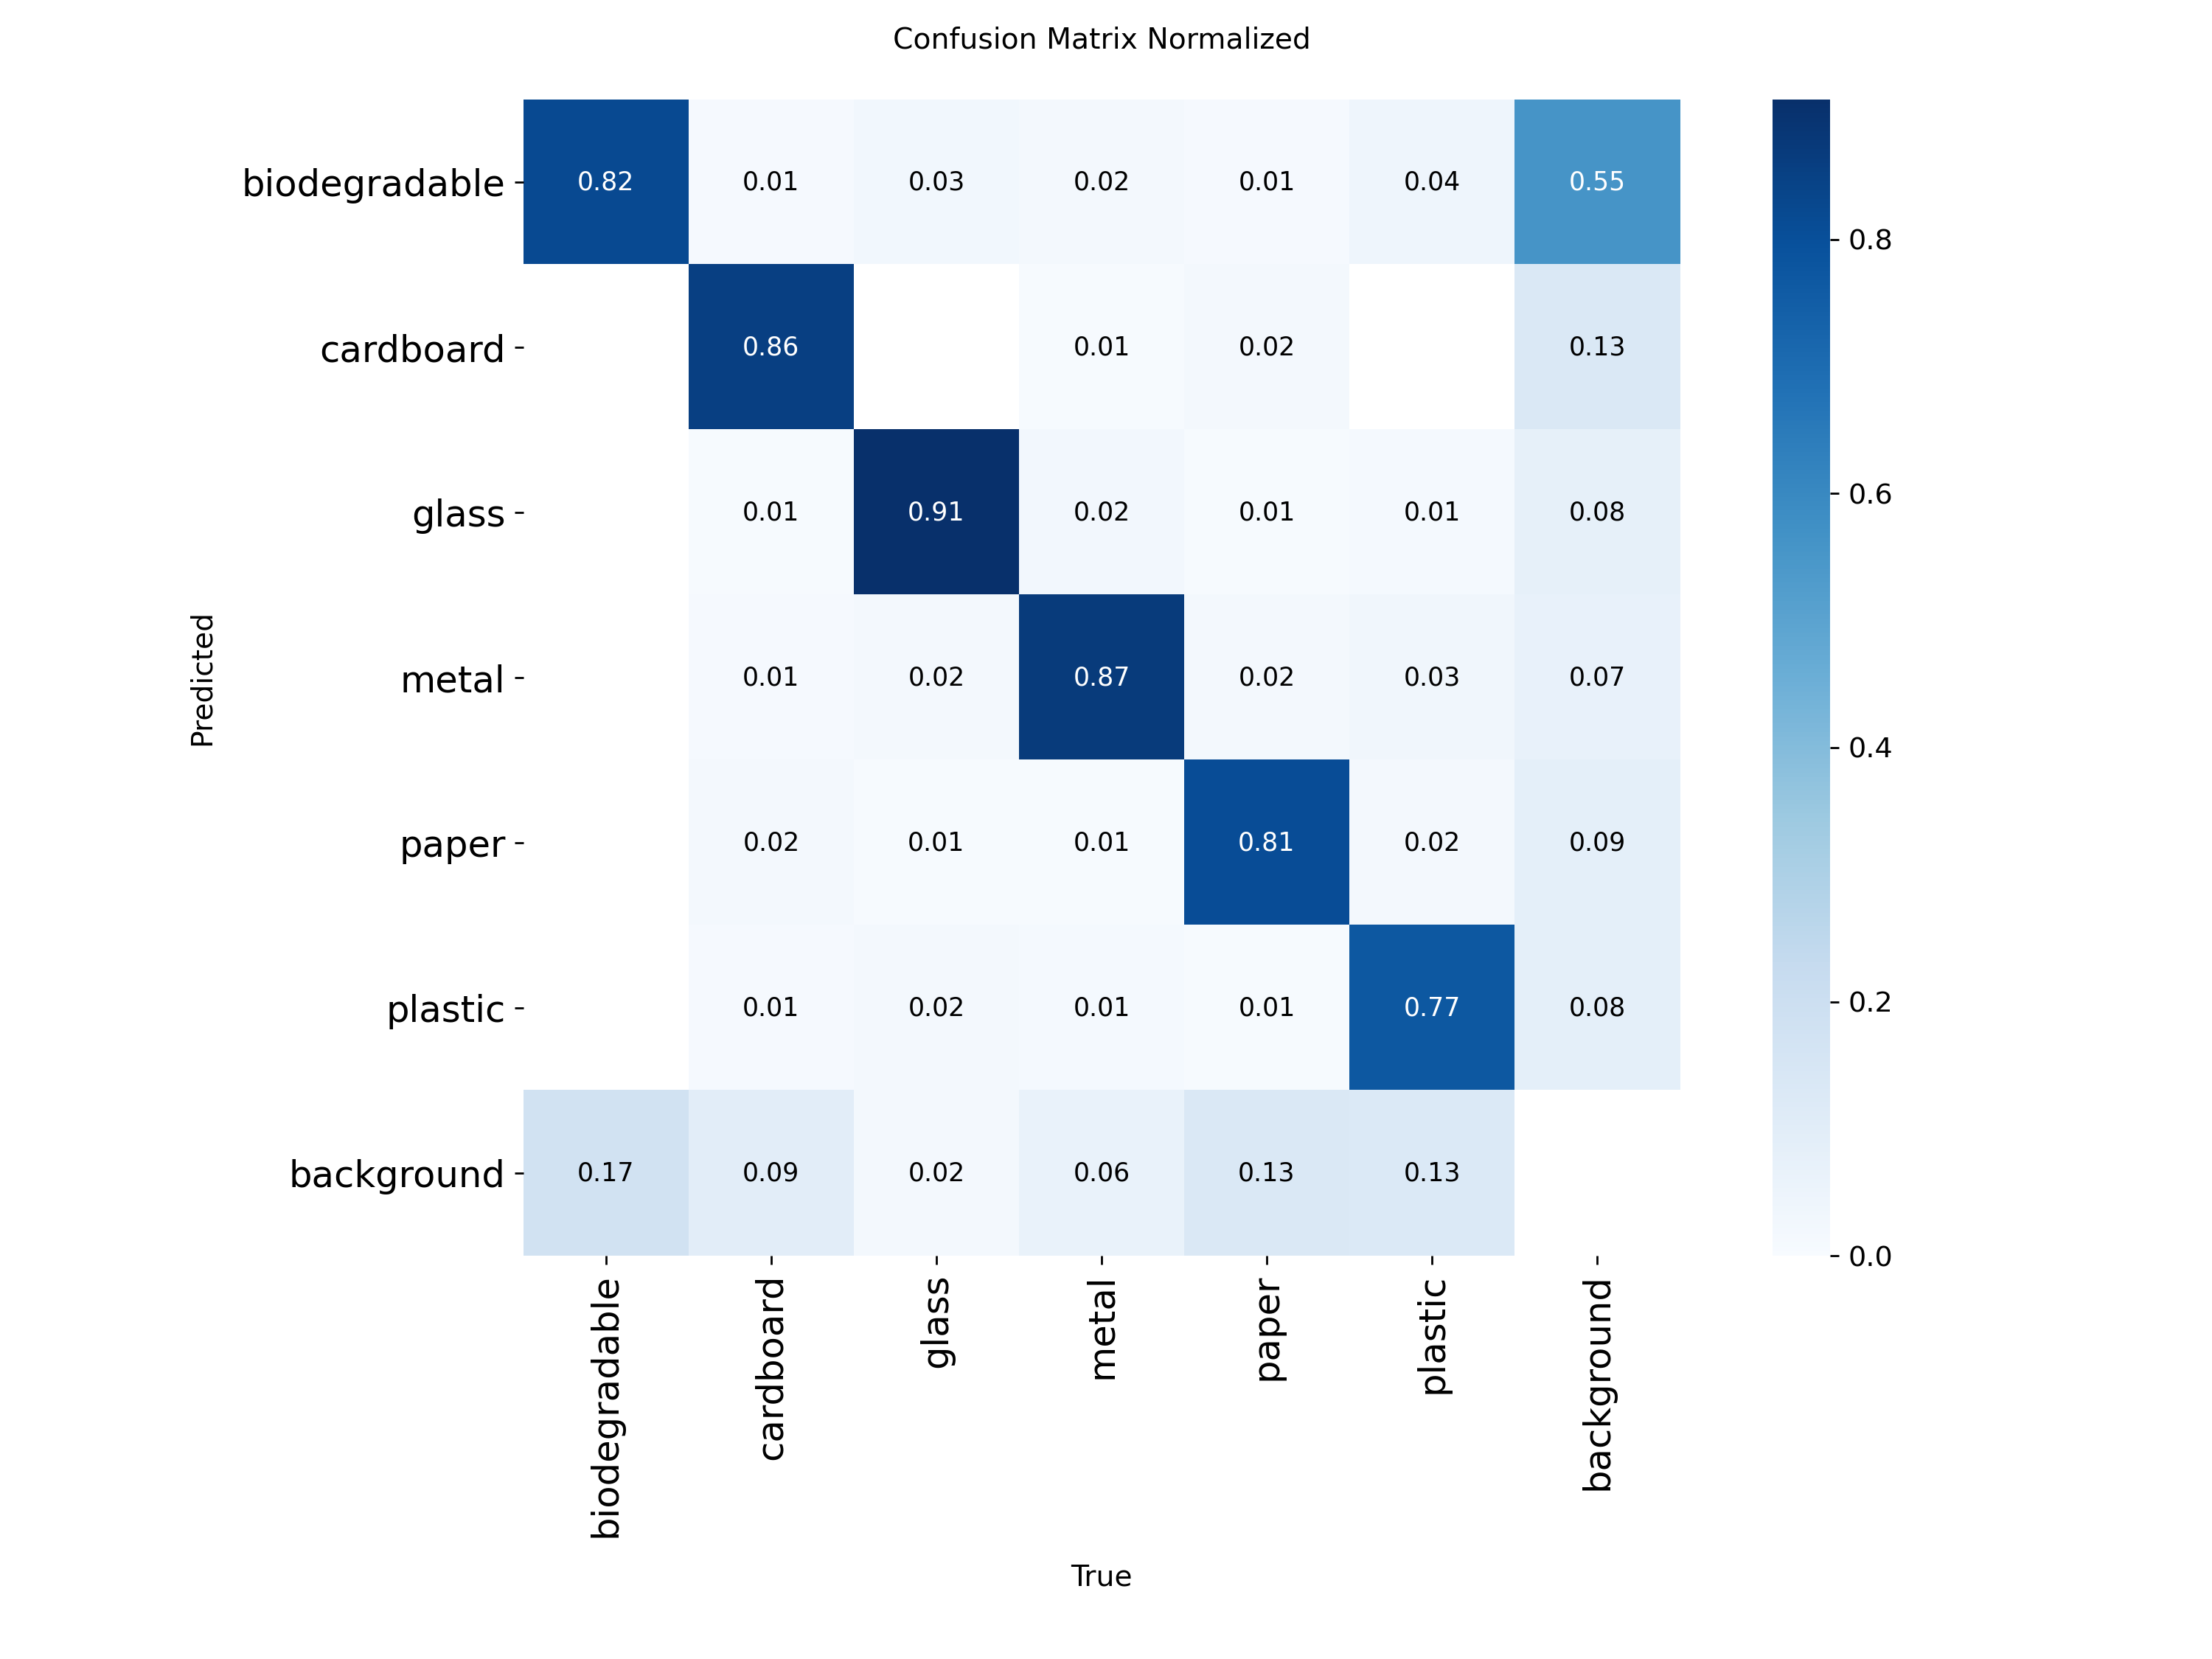

confusion_matrix.png


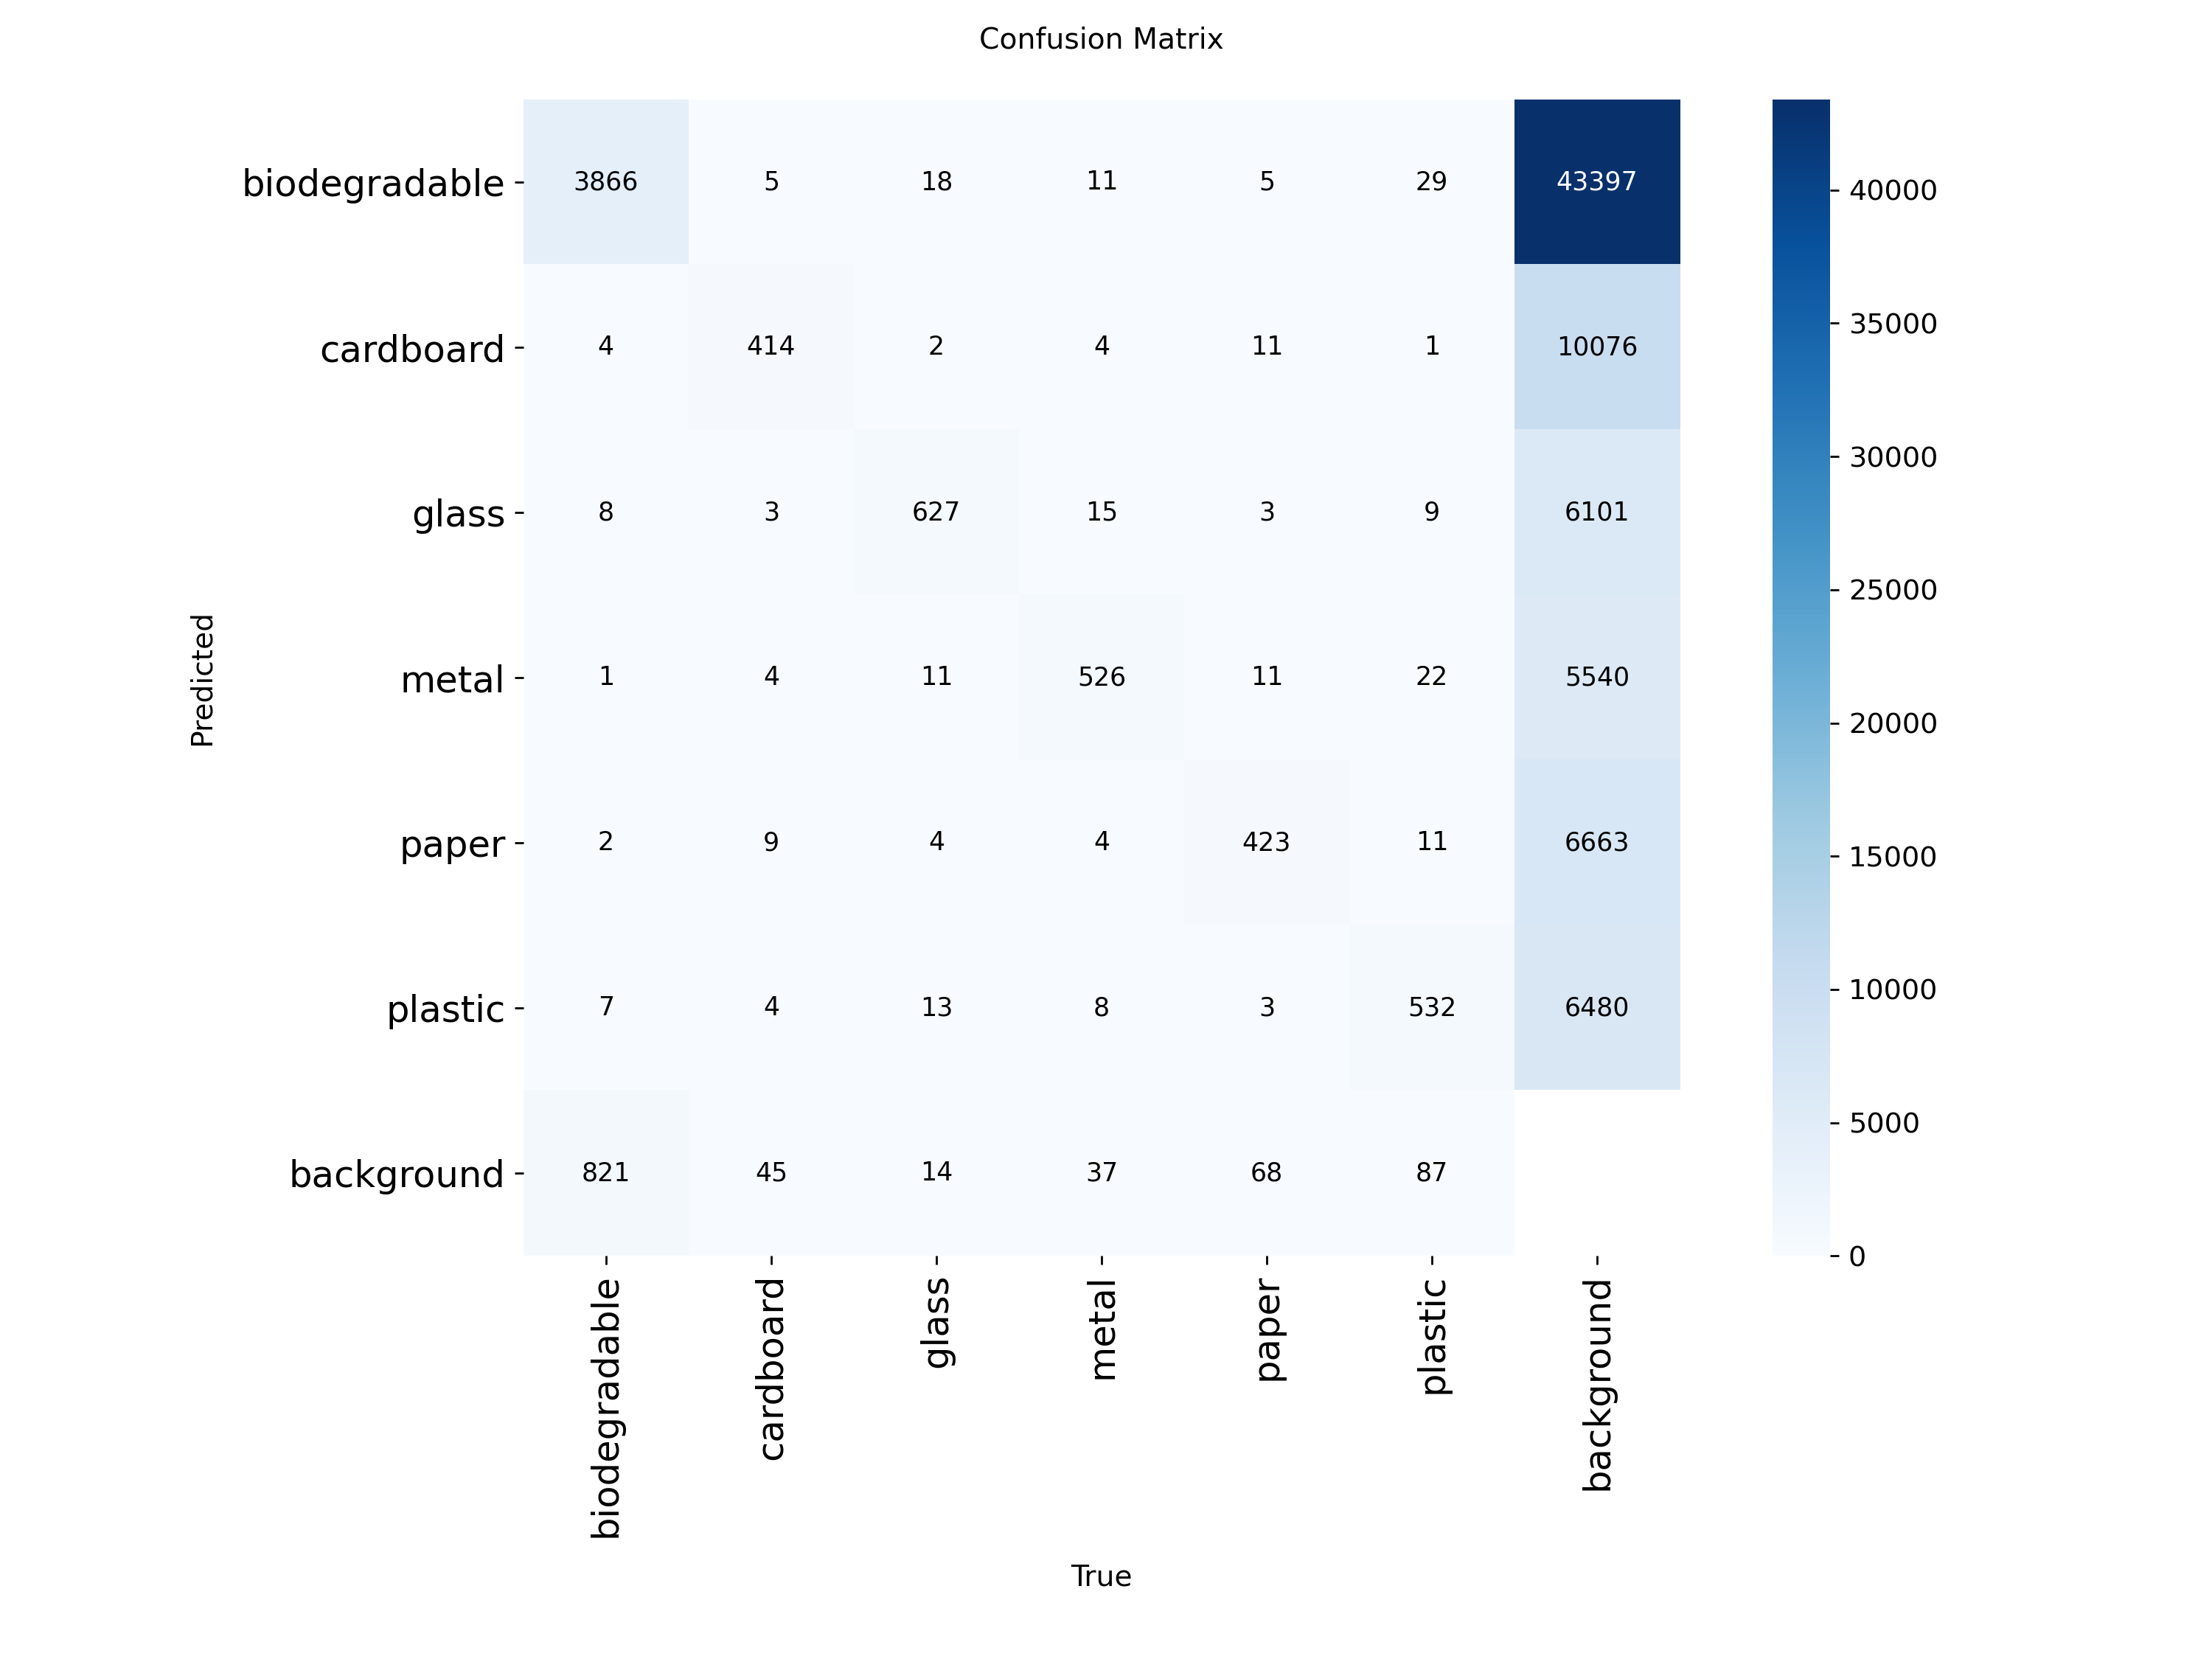

BoxPR_curve.png


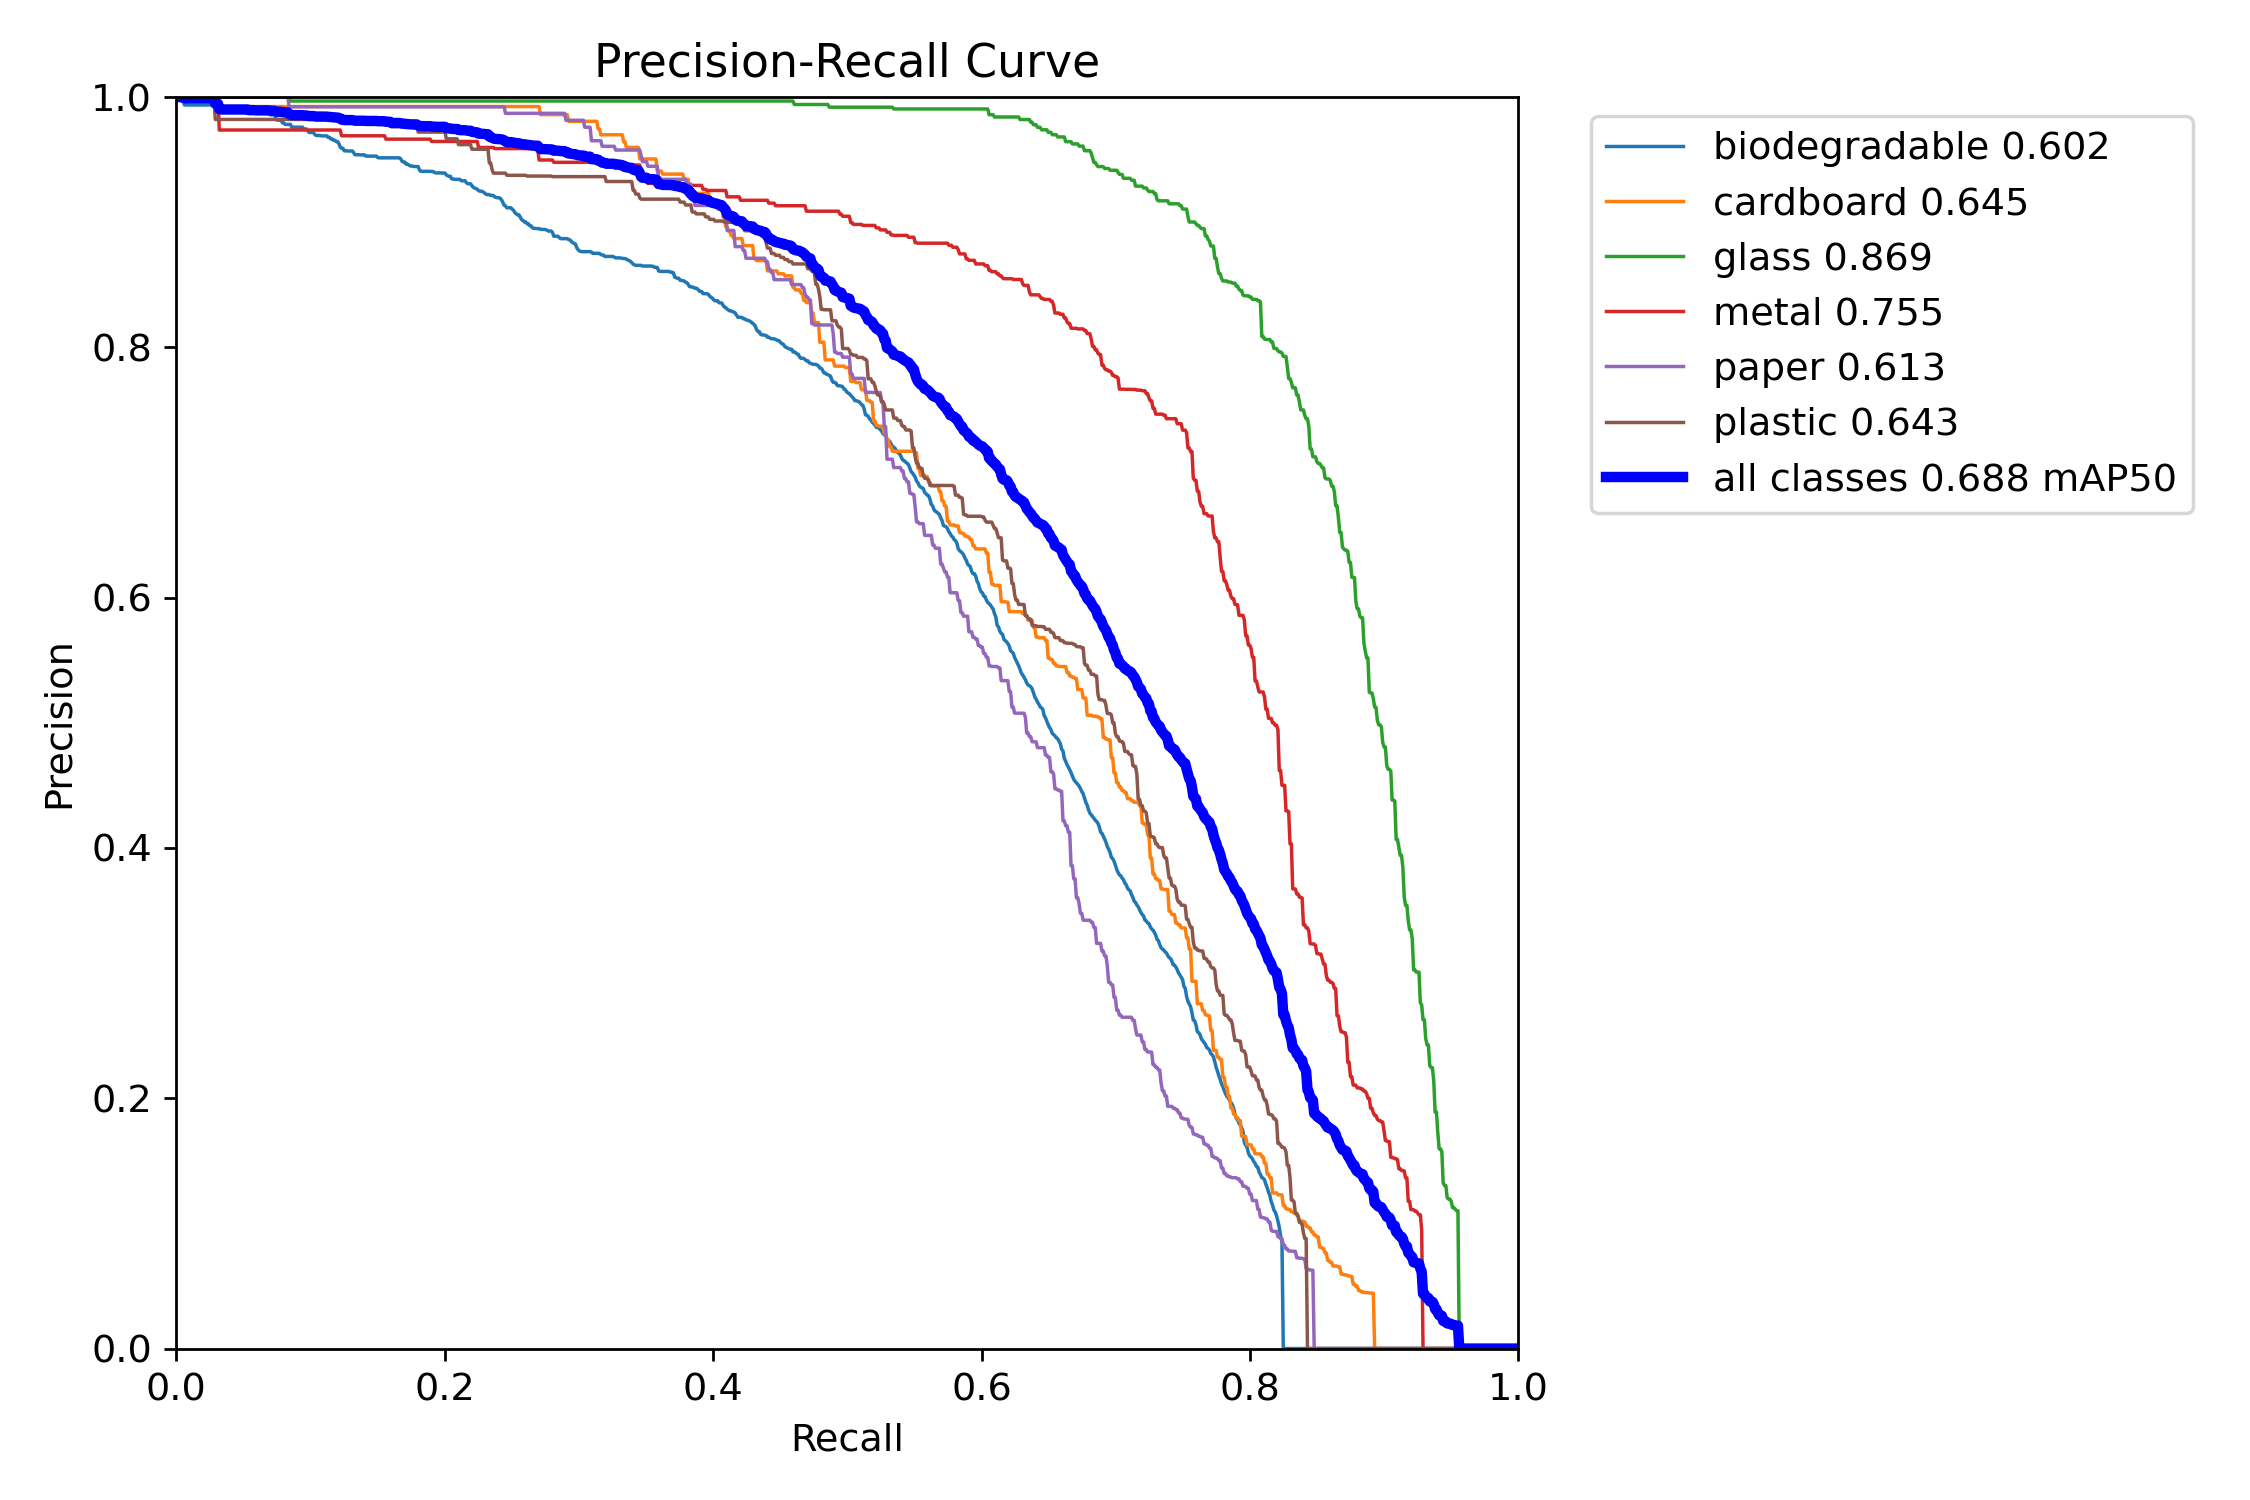

BoxF1_curve.png


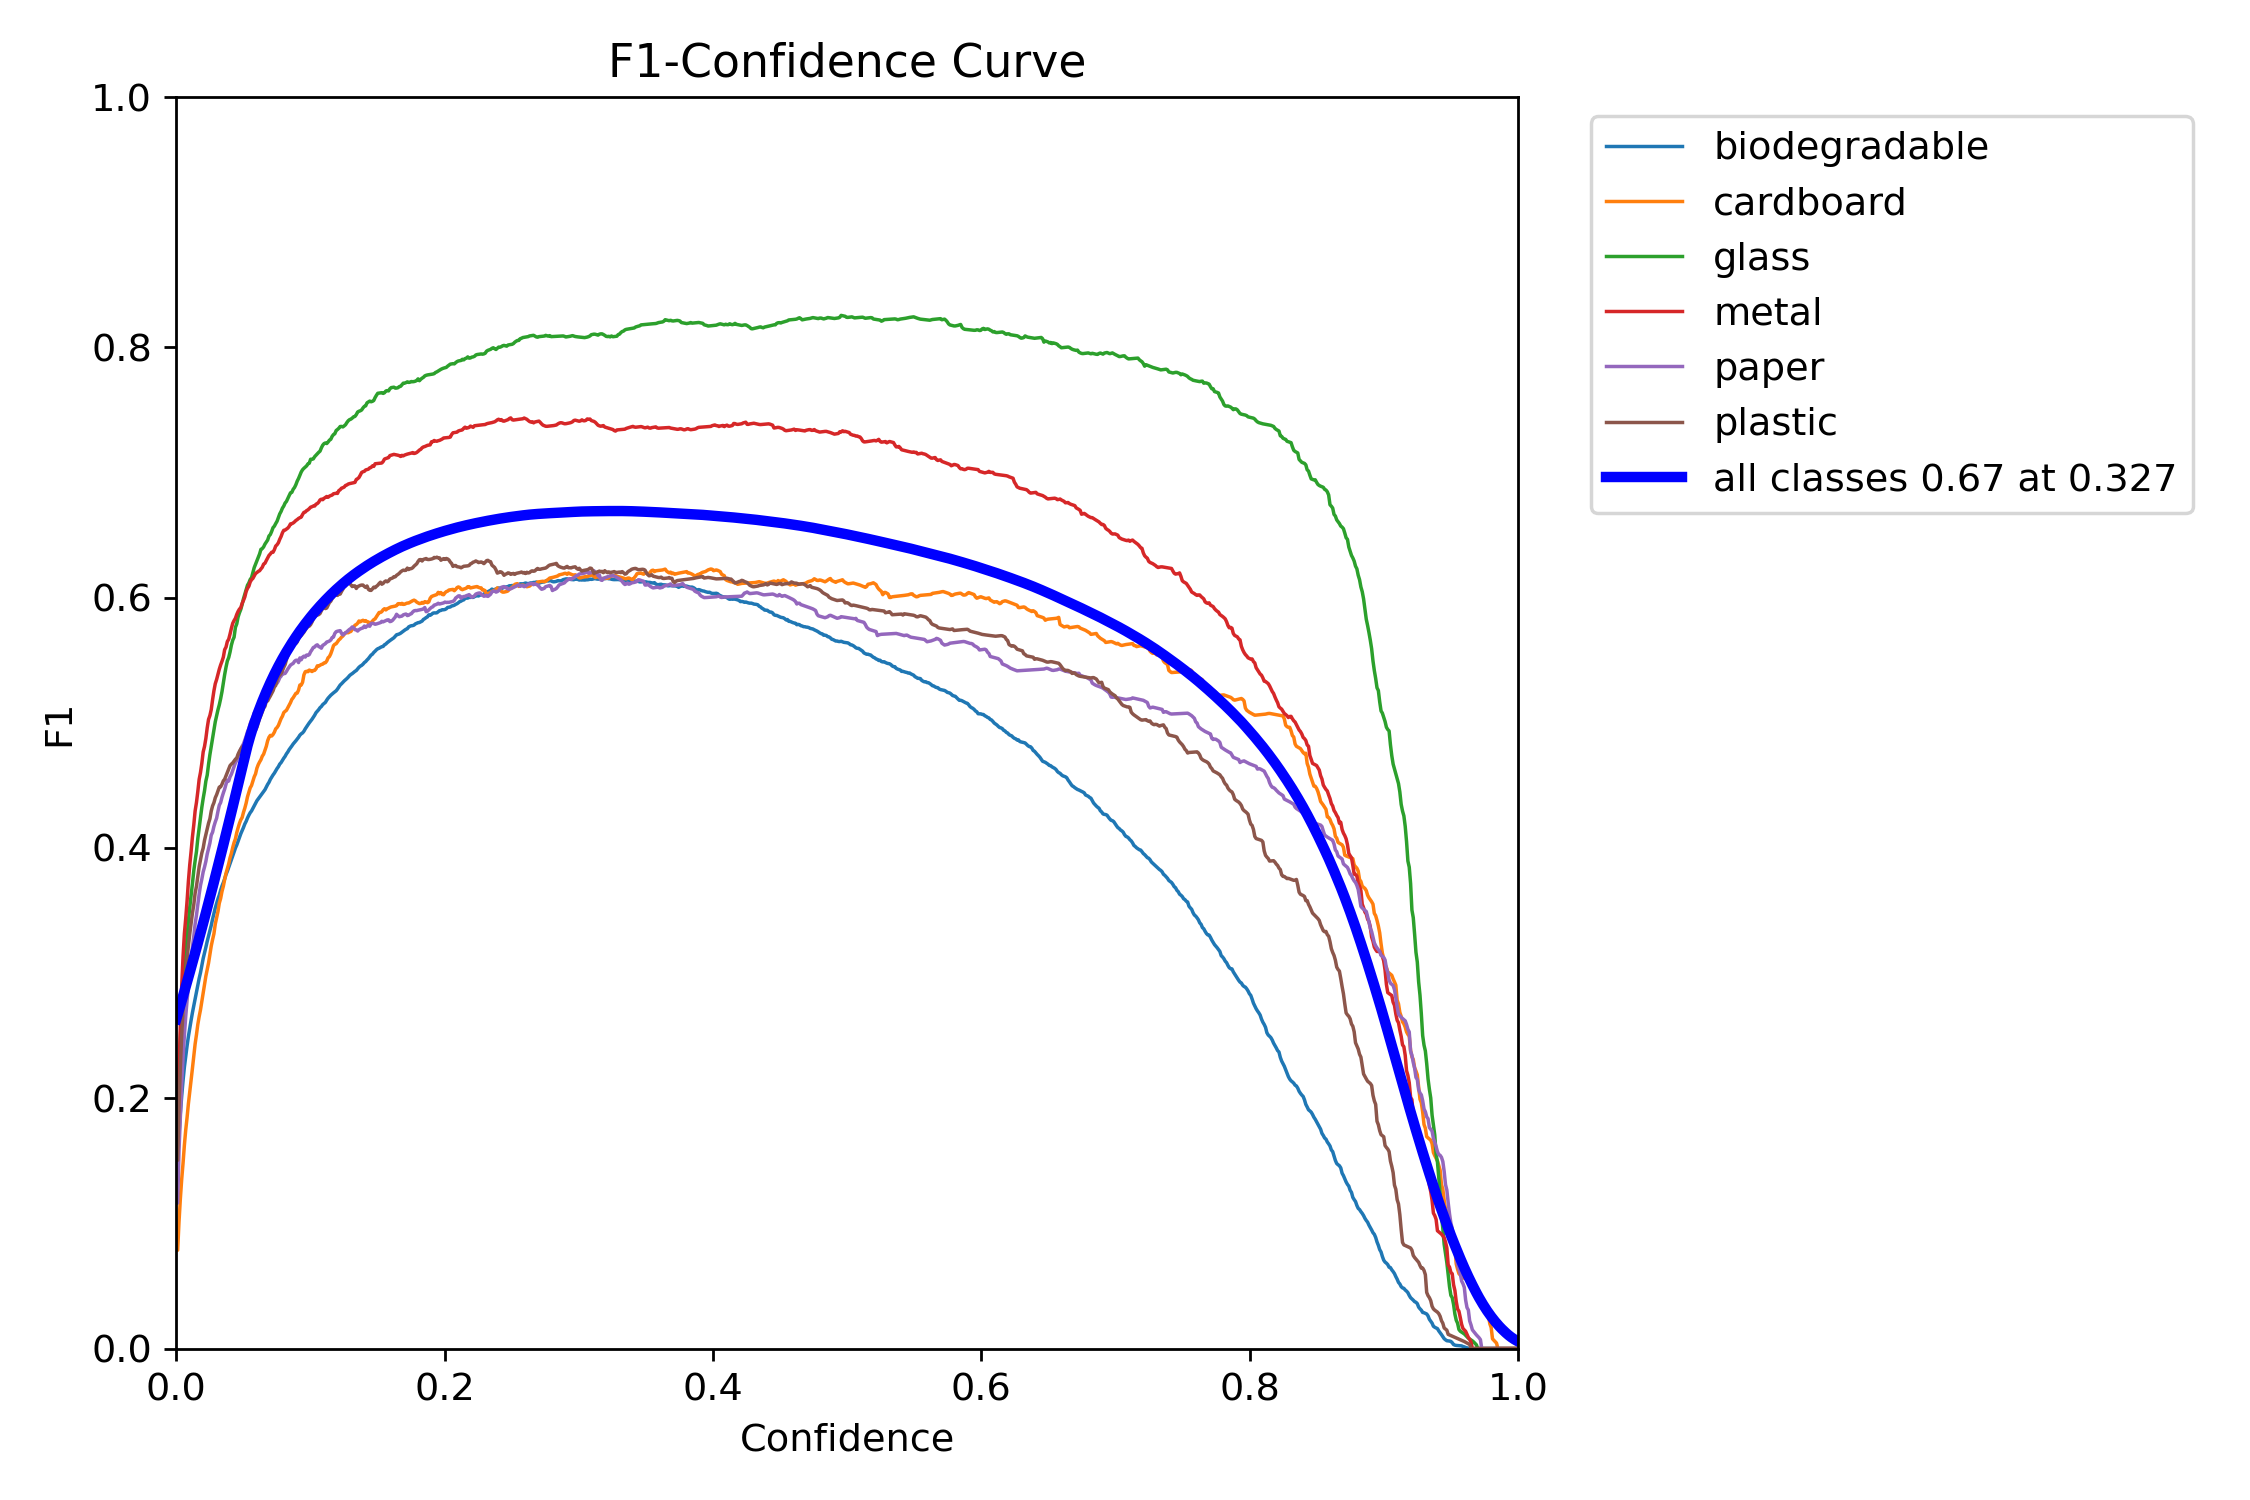

In [ ]:
from IPython.display import Image as IPyImage, display
for f in ["confusion_matrix_normalized.png", "confusion_matrix.png", "BoxPR_curve.png", "BoxF1_curve.png"]:
    if (TEST_DIR / f).exists():
        print(f); display(IPyImage(filename=str(TEST_DIR / f), width=650))

## 5.3 Interpretation of the test results

| | Precision | Recall | mAP50 | mAP50-95 |
|---|---|---|---|---|
| Validation | 0.778 | 0.604 | 0.688 | 0.482 |
| **Test** | **0.748** | **0.611** | **0.688** | **0.478** |

### Overall
- Validation and test results are almost identical, so the model generalises and was not tuned to the validation set.
- mAP50 (0.688) is much higher than mAP50-95 (0.478): objects are usually found, but the **box fit is not tight** at strict IoU, as expected with many small objects and inconsistent box granularity.
- Precision (0.748) is clearly higher than recall (0.611): the detector is **conservative and misses objects** rather than hallucinating them.

### Per class
| Class | Test boxes | P | R | AP50 | AP50-95 |
|---|---|---|---|---|---|
| glass | 689 | 0.809 | 0.808 | **0.869** | **0.672** |
| metal | 605 | 0.767 | 0.702 | 0.755 | 0.524 |
| cardboard | 484 | 0.657 | 0.583 | 0.645 | 0.463 |
| plastic | 691 | 0.769 | 0.520 | 0.643 | 0.423 |
| paper | 524 | 0.775 | 0.512 | 0.613 | 0.453 |
| biodegradable | 4,709 | 0.711 | 0.541 | 0.602 | **0.330** |

- **Best:** `glass` (distinct shape, often one object per image) and `metal`.
- **Worst:** `biodegradable` has the lowest AP50-95 (0.330), although it has the most training data. Its instances are tiny, numerous and vaguely defined (fruit pieces, leaves, food). `paper` and `plastic` have the lowest recall (about 0.51–0.52).
- `cardboard`, `paper` and `plastic` have only 484–691 test boxes, so their test scores vary noticeably from the validation scores (for example `paper` AP50 0.741 on validation vs 0.613 on test).

### Strengths
- Fast: 3.3 ms inference (about 5.8 ms including pre/post-processing) per image, 9.1 M parameters.
- Little class-to-class confusion (see the confusion matrix, off-diagonal entries ≤ 0.04).

### Limitations
- Low recall for small and crowded objects.
- Errors are dominated by missed objects and imprecise boxes, not by wrong class labels.
- The Ultralytics confusion matrix is computed at confidence 0.001, so it shows what is *findable* (for example 82 % of `biodegradable`), which is more optimistic than the operating point at confidence 0.25 used in section 6.

# 6. Visualization and Error Analysis (Task 3)

We run the detector on all test images with a deployment-like **confidence threshold of 0.25** and match predictions to ground truth (greedy, by confidence, IoU ≥ 0.5, same class).

* **TP** – matched prediction
* **FP** – prediction without match; subtyped as `duplicate` (box already matched), `wrong_class` (overlaps a GT of another class), `localisation` (overlaps GT with IoU 0.1–0.5), `background` (no object)
* **FN** – GT without match; subtyped as `misclassified` (some prediction with IoU ≥ 0.5 but wrong class) and `missed` (no prediction)

In [ ]:
CONF, MATCH_IOU = 0.25, 0.5
test_imgs = sorted((PROC_DIR / "test" / "images").glob("*.jpg"))

def load_gt(stem):
    g = by_img.get(stem)
    if g is None: return np.zeros(0, int), np.zeros((0, 4))
    return g["cls"].to_numpy(), np.stack([g.xc - g.w/2, g.yc - g.h/2, g.xc + g.w/2, g.yc + g.h/2], 1)

preds = {}
for r in tqdm(best.predict(source=[str(p) for p in test_imgs], imgsz=IMGSZ, conf=CONF, iou=0.7, max_det=500,
                           device=DEVICE, stream=True, verbose=False), total=len(test_imgs)):
    preds[Path(r.path).stem] = (r.boxes.cls.cpu().numpy().astype(int), r.boxes.conf.cpu().numpy(), r.boxes.xyxyn.cpu().numpy())

def cross_iou(a, b):
    if len(a) == 0 or len(b) == 0: return np.zeros((len(a), len(b)))
    x1 = np.maximum(a[:, None, 0], b[None, :, 0]); y1 = np.maximum(a[:, None, 1], b[None, :, 1])
    x2 = np.minimum(a[:, None, 2], b[None, :, 2]); y2 = np.minimum(a[:, None, 3], b[None, :, 3])
    inter = np.clip(x2 - x1, 0, None) * np.clip(y2 - y1, 0, None)
    aa = (a[:, 2] - a[:, 0]) * (a[:, 3] - a[:, 1]); ab = (b[:, 2] - b[:, 0]) * (b[:, 3] - b[:, 1])
    return inter / (aa[:, None] + ab[None, :] - inter + 1e-12)

gt_rows, fp_rows, per_image = [], [], {}
for stem in [p.stem for p in test_imgs]:
    gc, gb = load_gt(stem); pc, pf, pb = preds[stem]
    M = cross_iou(pb, gb)                                   # (pred, gt)
    matched_gt, matched_pred = {}, {}
    for pi in np.argsort(-pf):
        cand = [g for g in range(len(gc)) if g not in matched_gt and gc[g] == pc[pi] and M[pi, g] >= MATCH_IOU]
        if cand:
            g = max(cand, key=lambda k: M[pi, k]); matched_gt[g] = pi; matched_pred[pi] = g
    n_fp = n_fn = 0
    for g in range(len(gc)):
        area = (gb[g, 2] - gb[g, 0]) * (gb[g, 3] - gb[g, 1]) * IMGSZ**2
        if g in matched_gt: status, pcls = "TP", gc[g]
        else:
            n_fn += 1
            wrong = [pi for pi in range(len(pc)) if M[pi, g] >= MATCH_IOU and pc[pi] != gc[g]]
            if wrong: status, pcls = "misclassified", pc[max(wrong, key=lambda k: M[k, g])]
            else:     status, pcls = "missed", -1
        gt_rows.append((stem, gc[g], area, status, pcls))
    for pi in range(len(pc)):
        if pi in matched_pred: continue
        n_fp += 1
        if len(gc) == 0: t = "background"
        else:
            same = [g for g in range(len(gc)) if gc[g] == pc[pi] and M[pi, g] >= MATCH_IOU]
            oth  = [g for g in range(len(gc)) if gc[g] != pc[pi] and M[pi, g] >= MATCH_IOU]
            mx = M[pi].max()
            t = "duplicate" if same else "wrong_class" if oth else "localisation" if mx >= 0.1 else "background"
        fp_rows.append((stem, pc[pi], pf[pi], t))
    per_image[stem] = dict(n_gt=len(gc), n_pred=len(pc), fn=n_fn, fp=n_fp)

gtdf = pd.DataFrame(gt_rows, columns=["image", "cls", "area_px", "status", "pred_cls"])
fpdf = pd.DataFrame(fp_rows, columns=["image", "cls", "conf", "type"])
gtdf["size"] = size_bucket(gtdf["area_px"].values)
gtdf["cls_name"] = gtdf["cls"].map(dict(enumerate(CLASS_NAMES))); fpdf["cls_name"] = fpdf["cls"].map(dict(enumerate(CLASS_NAMES)))
pi_df = pd.DataFrame(per_image).T

TP = (gtdf.status == "TP").sum(); FN = (gtdf.status != "TP").sum(); FP = len(fpdf)
print(f"At conf={CONF}: TP={TP}  FP={FP}  FN={FN}  | precision={TP/(TP+FP):.3f}  recall={TP/(TP+FN):.3f}")

  0%|          | 0/1029 [00:00<?, ?it/s]

At conf=0.25: TP=4631  FP=2164  FN=3071  | precision=0.682  recall=0.601


## 6.1 Where are the errors? (per class, per object size, per type)

Recall at conf 0.25 by class and object size:


size,small,medium,large
cls_name,,,
biodegradable,0.339,0.680,0.816
cardboard,0.000,0.377,0.764
glass,0.608,0.667,0.910
metal,0.370,0.624,0.895
paper,0.120,0.254,0.751
plastic,0.232,0.547,0.794


Number of GT boxes:


size,small,medium,large
cls_name,,,
biodegradable,1891,2074,744
cardboard,31,122,331
glass,51,150,488
metal,73,237,295
paper,50,169,305
plastic,185,254,252


Overall recall by size:


,hit
size,
large,0.827
medium,0.627
small,0.328


False negatives by reason:


status,misclassified,missed
cls_name,,
biodegradable,6,2045
cardboard,13,172
glass,21,93
metal,12,154
paper,17,229
plastic,30,279


False positives by type:


type,background,duplicate,localisation,wrong_class
cls_name,,,,
biodegradable,340,152,853,25
cardboard,26,41,85,17
glass,22,43,84,17
metal,30,21,97,40
paper,5,30,72,16
plastic,25,23,74,26


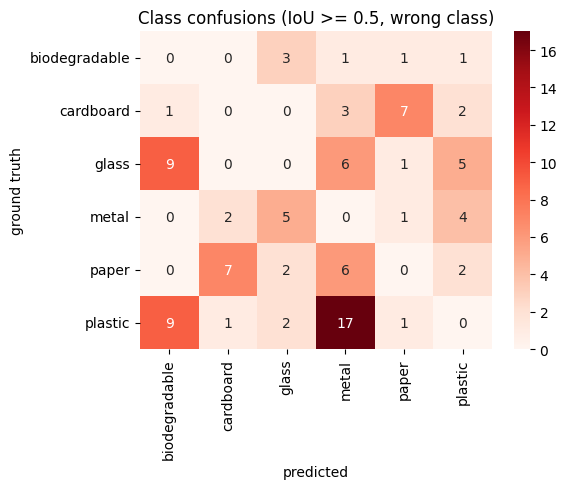

In [ ]:
rec = gtdf.assign(hit=(gtdf.status == "TP")).pivot_table(index="cls_name", columns="size", values="hit", aggfunc="mean").reindex(CLASS_NAMES)[["small", "medium", "large"]]
cnt = gtdf.groupby(["cls_name", "size"]).size().unstack().reindex(CLASS_NAMES)[["small", "medium", "large"]]
print("Recall at conf 0.25 by class and object size:"); display(rec.round(3))
print("Number of GT boxes:"); display(cnt)
print("Overall recall by size:"); display(gtdf.assign(hit=gtdf.status == "TP").groupby("size")["hit"].mean().round(3))

print("False negatives by reason:"); display(pd.crosstab(gtdf[gtdf.status != "TP"].cls_name, gtdf[gtdf.status != "TP"].status).reindex(CLASS_NAMES))
print("False positives by type:"); display(pd.crosstab(fpdf.cls_name, fpdf.type).reindex(CLASS_NAMES))

mis = gtdf[gtdf.status == "misclassified"]
cm = pd.crosstab(mis["cls"], mis["pred_cls"]).reindex(index=range(NC), columns=range(NC), fill_value=0)
plt.figure(figsize=(6, 5)); sns.heatmap(cm, annot=True, fmt="d", cmap="Reds", xticklabels=CLASS_NAMES, yticklabels=CLASS_NAMES)
plt.xlabel("predicted"); plt.ylabel("ground truth"); plt.title("Class confusions (IoU >= 0.5, wrong class)"); plt.tight_layout(); plt.show()

## 6.2 Select example images: correct / missed / incorrect

In [ ]:
pi_df["cat_correct"] = (pi_df.n_gt > 0) & (pi_df.fn == 0) & (pi_df.fp == 0)
pi_df["cat_missed"]  = pi_df.fn > 0
pi_df["cat_wrong"]   = pi_df.fp > 0
print("Images: all correct =", pi_df.cat_correct.sum(), "| with missed detections =", pi_df.cat_missed.sum(), "| with incorrect detections =", pi_df.cat_wrong.sum(), "| total =", len(pi_df))

def pick(mask, k=3, seed=SEED, max_gt=15):
    s = pi_df[mask & (pi_df.n_gt <= max_gt) & (pi_df.n_gt >= 1)].index.tolist()   # readable images (<= 15 boxes)
    if len(s) < k: s = pi_df[mask].index.tolist()
    return random.Random(seed).sample(s, min(k, len(s)))

examples = {"Correct detections": pick(pi_df.cat_correct), "Missed detections": pick(pi_df.cat_missed), "Incorrect detections": pick(pi_df.cat_wrong)}
{k: [s[:25] for s in v] for k, v in examples.items()}

Images: all correct = 527 | with missed detections = 353 | with incorrect detections = 431 | total = 1029


{'Correct detections': ['cardboard675_jpg.rf.a8e6b',
  'biodegradable188_jpg.rf.5',
  'metal1049_jpg.rf.24c3f090'],
 'Missed detections': ['biodegradable843_jpg.rf.0',
  'biodegradable1505_jpg.rf.',
  'glass2736_jpg.rf.6d599d16'],
 'Incorrect detections': ['plastic768_jpg.rf.d751af9',
  'biodegradable658_jpg.rf.b',
  'biodegradable1466_jpg.rf.']}

## 6.3 Visualize: ground truth (green) vs. prediction (red, with confidence)

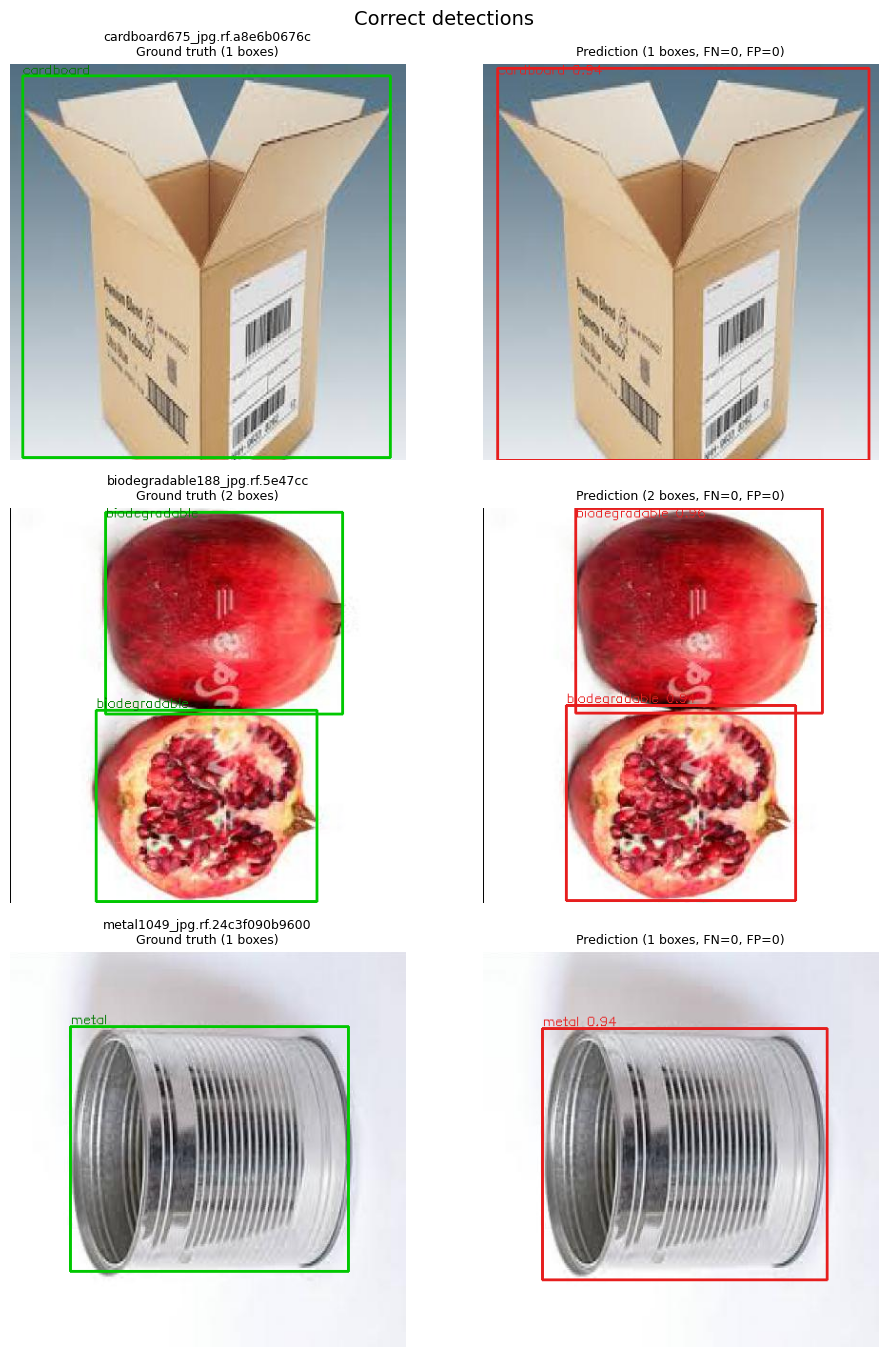

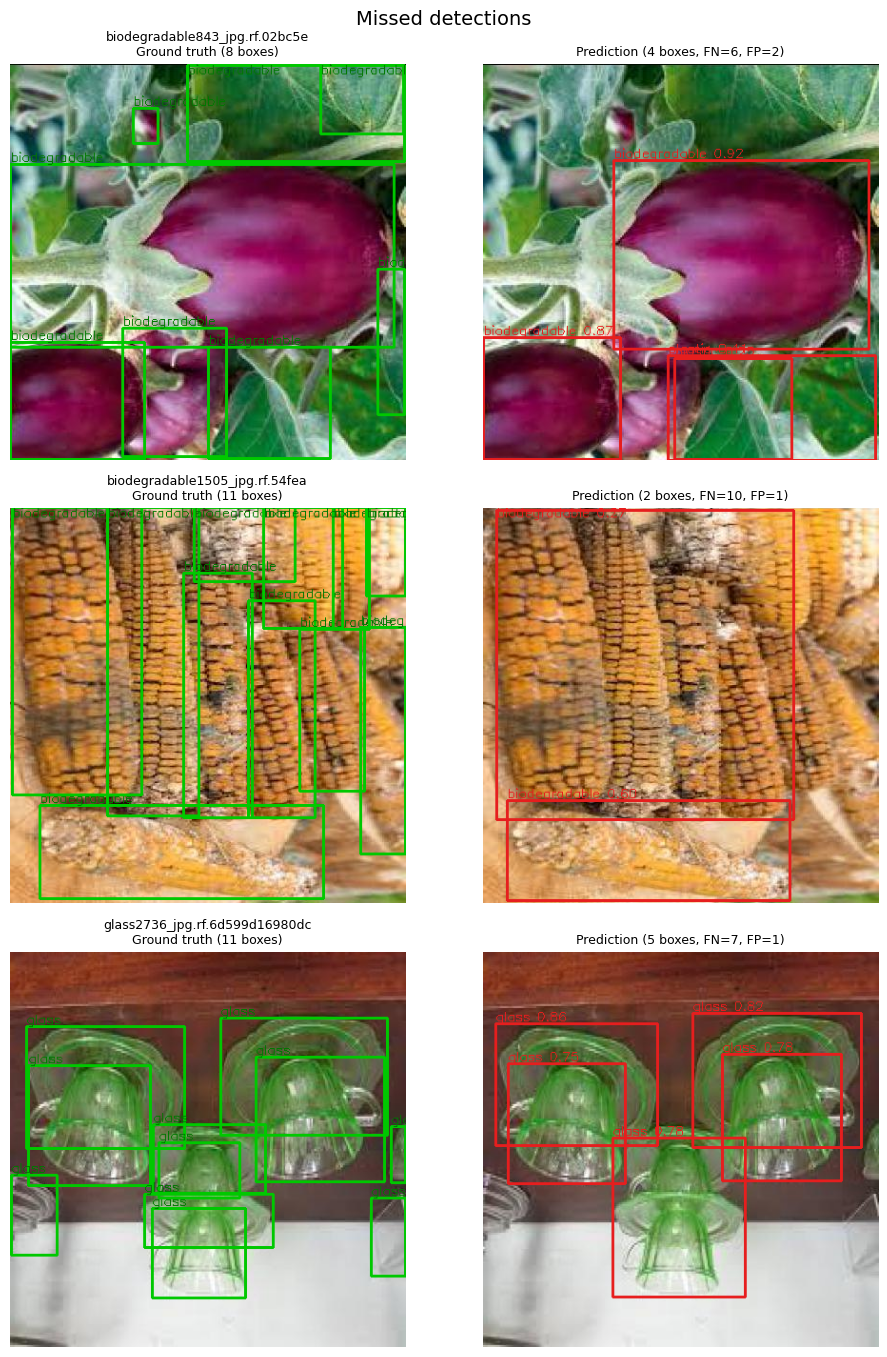

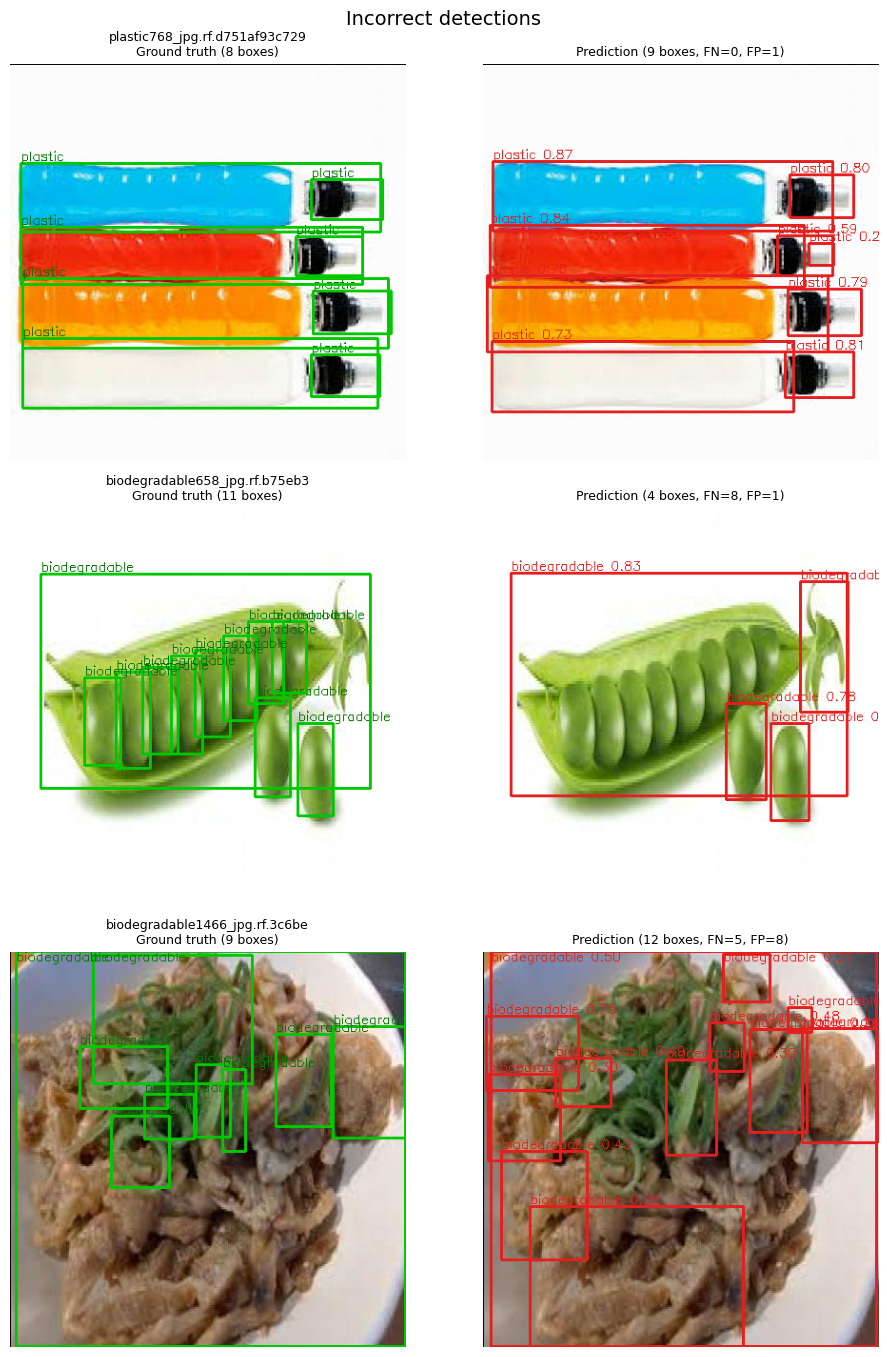

In [ ]:
def draw(stem, kind):
    im = cv2.cvtColor(cv2.imread(str(PROC_DIR / "test" / "images" / f"{stem}.jpg")), cv2.COLOR_BGR2RGB)
    out = im.copy(); H, W = im.shape[:2]
    if kind == "gt":
        gc, gb = load_gt(stem)
        for c, b in zip(gc, gb):
            x1, y1, x2, y2 = (b * [W, H, W, H]).astype(int)
            cv2.rectangle(out, (x1, y1), (x2, y2), (0, 200, 0), 2); cv2.putText(out, CLASS_NAMES[c], (x1, max(y1 - 3, 10)), cv2.FONT_HERSHEY_SIMPLEX, 0.45, (0, 120, 0), 1)
    else:
        pc, pf, pb = preds[stem]
        for c, f, b in zip(pc, pf, pb):
            x1, y1, x2, y2 = (b * [W, H, W, H]).astype(int)
            cv2.rectangle(out, (x1, y1), (x2, y2), (230, 30, 30), 2); cv2.putText(out, f"{CLASS_NAMES[c]} {f:.2f}", (x1, max(y1 - 3, 10)), cv2.FONT_HERSHEY_SIMPLEX, 0.45, (230, 30, 30), 1)
    return out

for title, stems in examples.items():
    fig, axes = plt.subplots(len(stems), 2, figsize=(10, 4.6 * len(stems)))
    axes = np.atleast_2d(axes)
    for r, s in enumerate(stems):
        d = per_image[s]
        axes[r, 0].imshow(draw(s, "gt")); axes[r, 0].set_title(f"{s[:30]}\nGround truth ({d['n_gt']} boxes)", fontsize=9)
        axes[r, 1].imshow(draw(s, "pred")); axes[r, 1].set_title(f"Prediction ({d['n_pred']} boxes, FN={d['fn']}, FP={d['fp']})", fontsize=9)
        for a in axes[r]: a.axis("off")
    plt.suptitle(title, fontsize=14); plt.tight_layout(); plt.show()

## 6.4 Error analysis and limitations

At confidence 0.25 (IoU ≥ 0.5): **TP = 4,631, FP = 2,164, FN = 3,071**, precision 0.68, recall 0.60.
527 of 1,029 test images (51 %) are fully correct, 353 contain missed objects and 431 contain false positives.

### What kind of errors?
| Error | Count | Insight |
|---|---|---|
| FN, no prediction at all ("missed") | 2,972 (97 % of FN) | the object is simply not found |
| FN, wrong class | 99 (3 %) | class confusion is rare |
| FP, poorly localised box | 1,265 (58 % of FP) | box overlaps an object with IoU 0.1–0.5 |
| FP, background | 448 | mostly `biodegradable` (340) |
| FP, duplicate box | 310 | NMS leaves a second box |
| FP, wrong class | 141 | |

### Dependence on object size (recall)
| | small | medium | large |
|---|---|---|---|
| Overall | **0.33** | 0.63 | 0.83 |
| `biodegradable` | 0.34 | 0.68 | 0.82 |
| `paper` | 0.12 | 0.25 | 0.75 |
| `cardboard` | 0.00 (31 boxes) | 0.38 | 0.76 |

Small objects are the main weakness. `biodegradable` alone accounts for 2,051 of the 3,071 missed objects (67 %) and 1,370 of the false positives, because it is the most numerous and smallest class.

### Observed examples and reasons
- **Corn cobs / eggplants (missed):** the ground truth has one box per cob or leaf, but the model predicts a few large boxes that merge neighbours. Dense, overlapping, similarly textured objects are hard to separate.
- **Stacked glass cups (missed):** transparent and nested objects with little contrast.
- **Peas and food plate (incorrect):** the annotation is inconsistent (one box for the whole pod *and* boxes for each pea, or huge boxes mixed with small ones). The model predicts many boxes with low confidence (0.4–0.5). Part of the "error" comes from the labels, not the model.
- **Plastic bottles (incorrect):** bottle and cap are annotated separately, and the model adds one extra overlapping cap box.

### Limitations
- Weak on small, dense or transparent objects.
- Noisy and inconsistent annotation granularity for `biodegradable`.
- Class names are inferred, and one dataset with a single 416 px resolution, so generalisation to real conveyor-belt images is unknown.
- Only 82 redundant copies were removed from val and test, and near-duplicate detection is threshold based, so a small residual leakage risk remains.

### Possible improvements
| Problem | Improvement |
|---|---|
| Small objects | higher input resolution (640+), tiling / SAHI, larger model (YOLOv5m/l) |
| Imbalance and weak minority classes | class-balanced sampling, loss re-weighting, more data |
| Label inconsistency | relabel or merge boxes (pod vs peas), noise-robust loss, label cleaning using confident model disagreements |
| Poor localisation and duplicate boxes | tune the NMS IoU threshold or use Soft-NMS, train longer |
| Remaining misses | lower the confidence threshold (use the F1-optimal one), test-time augmentation, ensembling |

## 6.5 Save everything to Google Drive (Colab deletes the runtime storage)

In [ ]:
DRIVE_OUT.mkdir(parents=True, exist_ok=True)
shutil.copytree(RUNS_DIR, DRIVE_OUT / "runs", dirs_exist_ok=True)
shutil.copy2(BEST_PT, DRIVE_OUT / "best.pt")
shutil.copy2(PROJECT_DIR / "duplicate_groups.json", DRIVE_OUT / "duplicate_groups.json")
final.to_csv(DRIVE_OUT / "test_metrics_per_class.csv")
print("Saved to", DRIVE_OUT)

Saved to /content/drive/MyDrive/Portfolio_1_results


---
# 7. Discussion & Conclusion <a id="conclusion"></a>

### What we did
- Analysed a 10,464-image waste dataset and found its risks: strong class imbalance, tiny and crowded objects, noisy label granularity and **near-duplicate images**.
- Built a **leakage-free, multi-label stratified** 70/20/10 split with cleaned labels.
- Trained **YOLOv5s** (COCO-pretrained, SGD, cosine LR, mosaic and colour/scale augmentation, 100 epochs).
- Evaluated on the untouched test set: **mAP50 = 0.688, mAP50-95 = 0.478, P = 0.748, R = 0.611**, about 6 ms per image.

### Key findings
1. Rigid objects with distinct shapes (`glass`, `metal`) are detected well, while `biodegradable` is the hardest class because of tiny, dense and loosely annotated instances.
2. Errors are mostly **missed objects** (97 % of FN) and **imprecisely placed boxes**, not class confusion.
3. Object size explains much of the performance: recall rises from 0.33 (small) to 0.83 (large).
4. Duplicate detection mattered: exact-file checks find nothing, but about 4 % of the images are near-copies.

### Outlook
Higher resolution or tiling, a larger backbone, class-balanced training and label cleaning are the most promising next steps.

## Individual Contributions

**1. Chandana Lakshmisagara Udayashankar:**

Assignment 2 – Task 1: Loss Function and Sampling Strategy

**2. Harshavardhini:**

Assignment 2 – Task 2: Analysis and Use of the Learned Embedding Space

**3. Sahana Mysore Venkatesh:**

Assignment 1 – Tasks 1, 2, and 3: Dataset Analysis and Training Pipeline, Model Training and Evaluation, and Visualization and Error Analysis.

**4. Shreyas Hosadurga Sadananda:**

Assignment 1 – Tasks 1, 2, and 3: Dataset Analysis and Training Pipeline, Model Training and Evaluation, and Visualization and Error Analysis.